# Photometry data preprocessing

This notebook lowpass filters the fluorescence signals, estimates slow photobleaching, regresses the isosbestic control against the signal to estimate shared artifacts, and computes dF/F or z-scores.

The current recording uses pyPhotometry `2EX_1EM_pulsed` acquisition: two excitation wavelengths and one emission detector. Here `analog_1` is treated as the activity-sensitive signal and `analog_2` as the isosbestic control; confirm that this matches the physical LED connections. The control is fluorescence under control excitation, not the LED-off baseline.

**File format:** pyPhotometry v1.1 pulsed files contain separate LED-on and LED-off samples for each channel. The importer below subtracts each channel's LED-off baseline and reconstructs the correct sample times and digital pulses. An older importer that assumes alternating channel samples will mix the channels and double the apparent duration.

This workflow was adapted from the Thomas Akam and Lauren Burgeno dLight/TdTomato example. Those original sensor labels and example-specific interpretations do not describe the current recording. Visually inspect each processing stage; a correlation with the control alone does not establish that all shared variation is movement.


Import the standard python modules needed for the analysis.

In [1]:
import os
import numpy as  np
import pylab as plt
from scipy.signal import medfilt, butter, filtfilt
from scipy.stats import linregress
from scipy.optimize import curve_fit, minimize

#set default plot properties
plt.rcParams['figure.figsize'] = [14, 12] # Make default figure size larger.
plt.rcParams['axes.xmargin'] = 0          # Make default margin on x axis zero.
plt.rcParams['axes.labelsize'] = 12     #Set default axes label size 
plt.rcParams['axes.titlesize']=15
plt.rcParams['axes.titleweight']='heavy'
plt.rcParams['ytick.labelsize']= 10
plt.rcParams['xtick.labelsize']= 10
plt.rcParams['legend.fontsize']=12
plt.rcParams['legend.markerscale']=2

Use the current official pyPhotometry [data importer](https://github.com/pyPhotometry/code/blob/master/tools/data_import.py), including v1.1 pulsed-file support.

In [2]:
# Function for opening pyPhotometry data files in Python.
# Copyright (c) Thomas Akam 2018-2025. Licensed under GNU GPL v3.
# Official importer retrieved 2026-10-01:
# https://github.com/pyPhotometry/code/blob/master/tools/data_import.py

import os
import json
import numpy as np
from scipy.signal import butter, filtfilt
from packaging.version import parse as parse_version



def import_ppd(file_path, low_pass=20, high_pass=0.01):
    """Function to import pyPhotometry binary data files into Python. The high_pass
    and low_pass arguments determine the frequency in Hz of highpass and lowpass
    filtering applied to the filtered analog signals. To disable highpass or lowpass
    filtering set the respective argument to None.  Returns a dictionary with the
    following items:
        'filename'      - Data filename
        'subject_ID'    - Subject ID
        'date_time'     - Recording start date and time (ISO 8601 format string)
        'end_time'      - Recording end date and time (ISO 8601 format string)
        'mode'          - Acquisition mode
        'sampling_rate' - Sampling rate (Hz)
        'LED_current'   - Current for LEDs 1 and 2 (mA)
        'version'       - Version number of pyPhotometry
        For each analog signal (x in [1, n_analog_signals]):
            'analog_x'            - Raw analog signal (volts)
            'analog_x_filt'       - Filtered analog signal (volts)
            In pulsed acqusition modes with pyPhotometry version >= 1.1:
            'analog_x_raw_LED_on'   - Analog signal before baseline subtraction (volts)
            'analog_x_raw_baseline' - Baseline signal with LED off (volts).
            If signal clipping can be evaluated (not pulsed mode with version < 1.1):
            'analog_x_clipping' - Samples where analog signal was clipping (bool)
        For each digital signal (y in [1, n_digital_signals]):
            'digital_y'     - Digital signal
            'pulse_inds_y'  - Locations of rising edges on digital signal (samples).
            'pulse_times_y' - Times of rising edges on digital signal (ms).
    """

    # Read data from file --------------------------------------------------------------
    with open(file_path, "rb") as f:
        header_size = int.from_bytes(f.read(2), "little")
        data_header = f.read(header_size)
        data = np.frombuffer(f.read(), dtype=np.dtype("<u2"))

    # Extract header information -------------------------------------------------------
    header_dict = json.loads(data_header)
    sampling_rate = header_dict["sampling_rate"]
    volts_per_division = header_dict["volts_per_division"][0]
    acquisition_mode = header_dict["mode"]
    version = parse_version(header_dict["version"])

    # Get version specfic info ---------------------------------------------------------

    if version < parse_version("1.0"):
        n_analog_signals = 2
        n_digital_signals = 2
        pulsed_mode = "time div" in acquisition_mode
    else:
        n_analog_signals = header_dict["n_analog_signals"]
        n_digital_signals = header_dict["n_digital_signals"]
        pulsed_mode = "pulsed" in acquisition_mode

    if version >= parse_version("1.1"):
        has_baselines = pulsed_mode
        ADC_max_value = header_dict["ADC_max_value"]
    else:
        has_baselines = False
        ADC_max_value = 1 << 15

    # Extract signals ------------------------------------------------------------------
    analog = data >> 1  # Analog signal is most significant 15 bits.
    digital = ((data & 1) == 1).astype(int)  # Digital signal is least significant bit.
    clip_threshold = 0.98 * ADC_max_value * volts_per_division
    if has_baselines:  # Raw LED-on and LED-off (baseline) samples saved seperately.
        LED_on_sigs = [analog[2 * a :: 2 * n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        baselines = [analog[2 * a + 1 :: 2 * n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        # Compute baseline subtracted signals by subtracting baseline from LED-on signal.
        analog_sigs = [LED_on_sig - baseline for LED_on_sig, baseline in zip(LED_on_sigs, baselines)]
        # Identify any samples where signal is clipping
        sigs_clipping = [
            np.maximum(LED_on_sig, baseline) > clip_threshold for LED_on_sig, baseline in zip(LED_on_sigs, baselines)
        ]
        digital_sigs = [digital[2 * d :: 2 * n_analog_signals] for d in range(n_digital_signals)]
    else:  # Any baseline subtraction was done before saving signals.
        analog_sigs = [analog[a::n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        digital_sigs = [digital[d::n_analog_signals] for d in range(n_digital_signals)]
        sigs_clipping = [analog_sig > clip_threshold for analog_sig in analog_sigs] if not pulsed_mode else None

    # Compute sample times relative to start of recording (ms) -------------------------
    time = np.arange(analog_sigs[0].shape[0]) * 1000 / sampling_rate

    # Filter signals with specified high and low pass frequencies (Hz) -----------------
    if low_pass and high_pass:
        b, a = butter(2, np.array([high_pass, low_pass]) / (0.5 * sampling_rate), "bandpass")
    elif low_pass:
        b, a = butter(2, low_pass / (0.5 * sampling_rate), "low")
    elif high_pass:
        b, a = butter(2, high_pass / (0.5 * sampling_rate), "high")
    if low_pass or high_pass:
        analogs_filt = [filtfilt(b, a, analog_sig) for analog_sig in analog_sigs]
    else:
        analogs_filt = [None] * len(analog_sigs)

    # Extract rising edges for digital inputs ------------------------------------------
    pulse_inds = [1 + np.where(np.diff(digital_sig) == 1)[0] for digital_sig in digital_sigs]
    pulse_times = [pulse_ind * 1000 / sampling_rate for pulse_ind in pulse_inds]

    # Return signals + header information as a dictionary ------------------------------
    data_dict = {
        "filename": os.path.basename(file_path),
        "time": time,
    }
    for a in range(n_analog_signals):
        data_dict[f"analog_{a+1}"] = analog_sigs[a]
        data_dict[f"analog_{a+1}_filt"] = analogs_filt[a]
        if has_baselines:
            data_dict[f"analog_{a+1}_raw_LED_on"] = LED_on_sigs[a]
            data_dict[f"analog_{a+1}_raw_baseline"] = baselines[a]
        if sigs_clipping:
            data_dict[f"analog_{a+1}_clipping"] = sigs_clipping[a]
    for d in range(n_digital_signals):
        data_dict[f"digital_{d+1}"] = digital_sigs[d]
        data_dict[f"pulse_inds_{d+1}"] = pulse_inds[d]
        data_dict[f"pulse_times_{d+1}"] = pulse_times[d]
    data_dict.update(header_dict)
    return data_dict


Import the photometry recording and its digital event channels.

In [3]:
data_folder = os.path.join("..", "data")
data_filename = "RT_64_N-2026-10-01-151306.ppd"
behavior_data_filename = "RT_64_N-2026-10-01-151309.tsv"
# data_filename = "RT_65_LR-2026-10-01-153922.ppd"
# behavior_data_filename = "RT_65_LR-2026-10-01-153924.tsv"
data_path = os.path.join(data_folder, data_filename)
data = import_ppd(data_path)

Extract the baseline-subtracted signal and isosbestic control, session time, and sampling rate.

In [4]:
signal_raw = data['analog_1']
background_raw = data['analog_2']
time_seconds = data['time']/1000
sampling_rate = data['sampling_rate']

In [5]:
# Import checks: duration, channel levels, clipping, and digital pulse counts.
from datetime import datetime

print(f"File: {data['filename']} | pyPhotometry {data['version']} | {data['mode']}")
print(f"Samples/channel: {len(signal_raw):,} | Sampling rate: {sampling_rate:g} Hz")
print(f"Sample duration: {len(signal_raw) / sampling_rate:.3f} s")
if data.get('end_time'):
    header_duration = (datetime.fromisoformat(data['end_time']) -
                       datetime.fromisoformat(data['date_time'])).total_seconds()
    print(f"Header duration: {header_duration:.3f} s")
for channel, label in [(1, 'Signal'), (2, 'Isosbestic control')]:
    values = data[f'analog_{channel}']
    print(f"{label}: median {np.median(values):.6f} V; "
          f"range {values.min():.6f} to {values.max():.6f} V")
    clipping = data.get(f'analog_{channel}_clipping')
    if clipping is not None:
        print(f"  Near-clipping samples: {np.count_nonzero(clipping)}")
    print(f"  Digital {channel} rising edges: {len(data[f'pulse_inds_{channel}'])}")


File: RT_64_N-2026-10-01-151306.ppd | pyPhotometry 1.1 | 2EX_1EM_pulsed
Samples/channel: 20,028 | Sampling rate: 130 Hz
Sample duration: 154.062 s
Header duration: 154.064 s
Signal: median 2.714316 V; range 2.695590 to 2.735268 V
  Near-clipping samples: 0
  Digital 1 rising edges: 30
Isosbestic control: median 2.648320 V; range 2.624635 to 2.675042 V
  Near-clipping samples: 0
  Digital 2 rising edges: 0


In [6]:
time_seconds

array([0.00000000e+00, 7.69230769e-03, 1.53846154e-02, ...,
       1.54038462e+02, 1.54046154e+02, 1.54053846e+02])

# Raw signals

Plot the signal and isosbestic fluorescence control after LED-off baseline subtraction. The two y-axes scale independently.

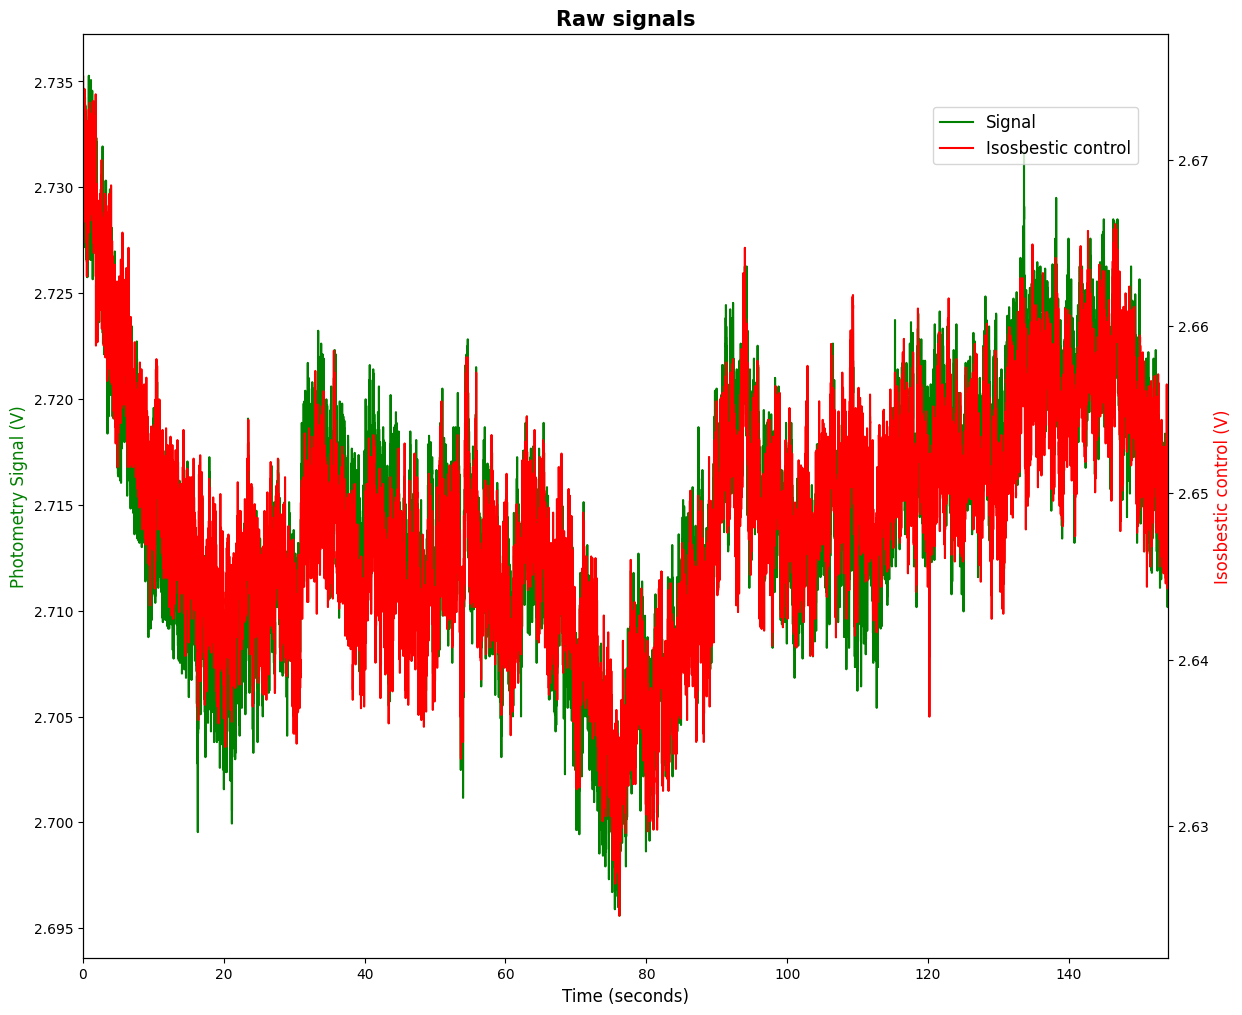

In [7]:
# Plot signals

fig,ax1=plt.subplots()  # create a plot to allow for dual y-axes plotting
plot1=ax1.plot(time_seconds, signal_raw, 'g', label='Signal') # Plot signal on left y-axis
ax2=plt.twinx()# create a right y-axis, sharing x-axis on the same plot
plot2=ax2.plot(time_seconds, background_raw, 'r', label='Isosbestic control') # Plot isosbestic control on right y-axis

#ax1.set_ylim(0.24, 0.32)
#ax2.set_ylim(0.24, 0.32)
ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Raw signals')

lines = plot1 + plot2 #line handle for legend
labels = [l.get_label() for l in lines]  #get legend labels
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.98, 0.93)) #add legend

# Denoising

We lowpass filter the signals to reduce high frequency noise, using a zero phase filter with a 10Hz cutoff frequency.

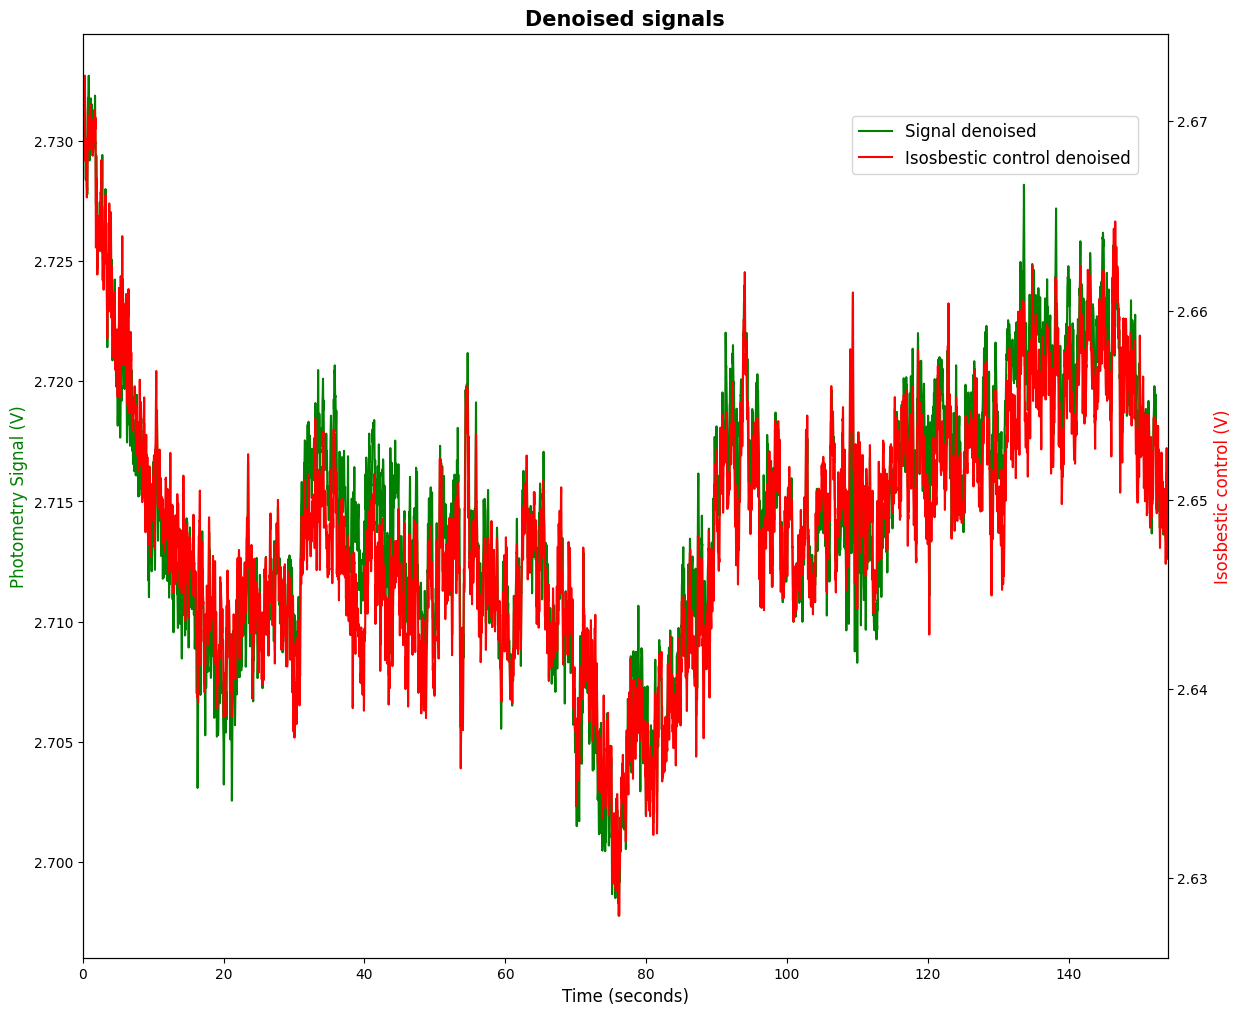

In [8]:
# Lowpass filter - zero phase filtering (with filtfilt) is used to avoid distorting the signal.
b,a = butter(2, 10, btype='low', fs=sampling_rate)
signal_denoised = filtfilt(b,a, signal_raw)
background_denoised = filtfilt(b,a, background_raw)

fig,ax1=plt.subplots()
plot1=ax1.plot(time_seconds, signal_denoised, 'g', label='Signal denoised')
ax2=plt.twinx()
plot2=ax2.plot(time_seconds, background_denoised, 'r', label='Isosbestic control denoised')

#ax1.set_ylim(0.24, 0.32)
#ax2.set_ylim(0.24, 0.32)
ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Denoised signals')

lines = plot1+plot2 #line handle for legend
labels = [l.get_label() for l in lines]  #get legend labels
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.98, 0.92)) #add legend

Let's zoom in on the x axis to see how the lowpass filtering has smoothed the signals.

(100.0, 154.05384615384617)

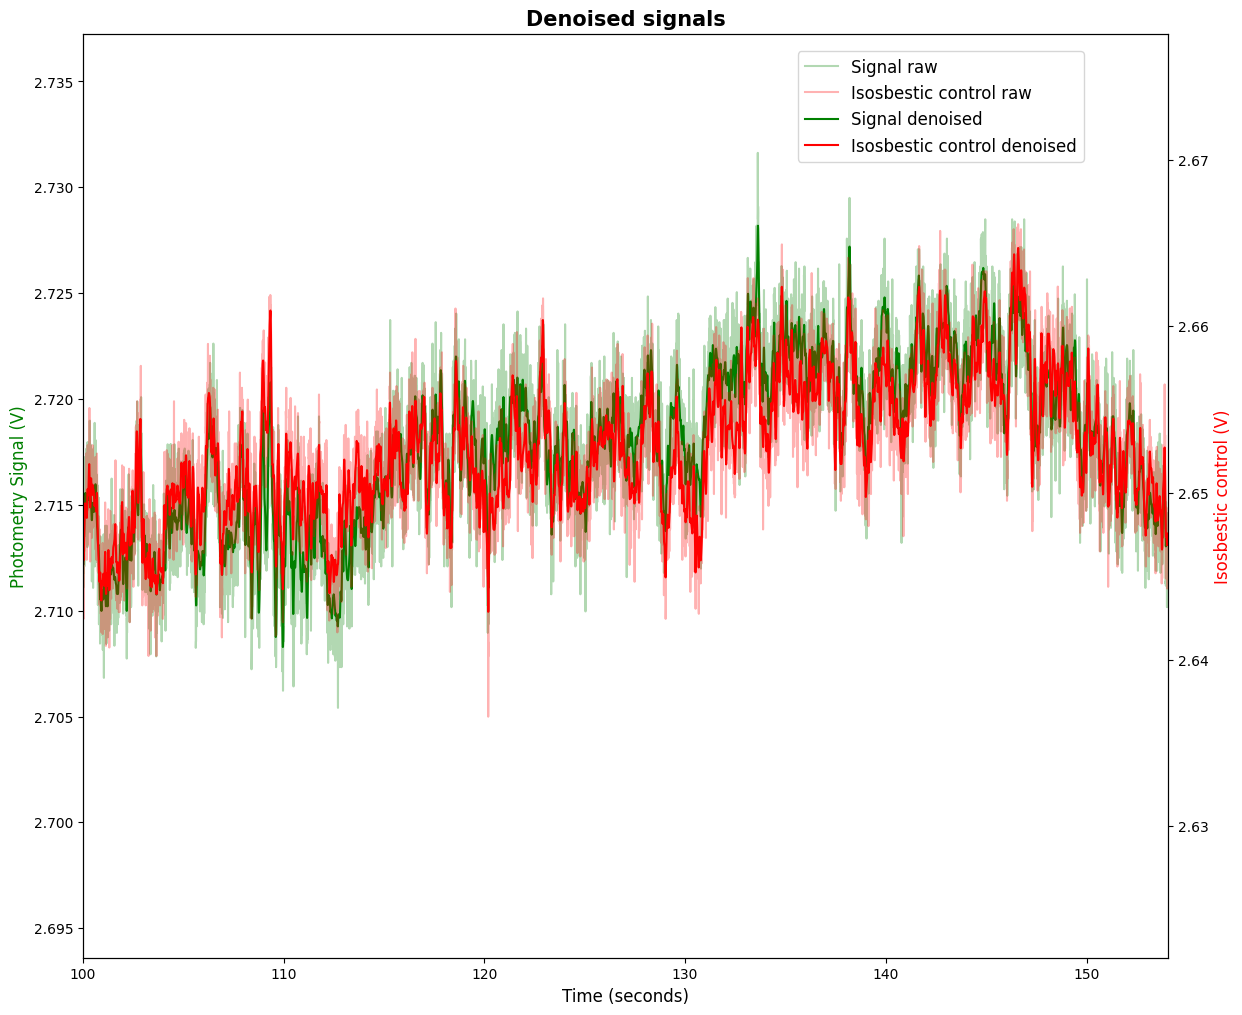

In [9]:
fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_raw, color='g', alpha=0.3, label='Signal raw')
ax2=plt.twinx()
plot2=ax2.plot(time_seconds, background_raw, color='r', alpha=0.3, label='Isosbestic control raw') 
plot3=ax1.plot(time_seconds, signal_denoised, color='g', label='Signal denoised') 
plot4=ax2.plot(time_seconds, background_denoised, color='r', label='Isosbestic control denoised') 

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Denoised signals')

lines = plot1+plot2 + plot3 + plot4
labels = [l.get_label() for l in lines]
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.93, 0.99))
ax1.set_xlim(100, min(160, time_seconds[-1])) # 60 sec window
#ax1.set_ylim(0.24, 0.32)
#ax2.set_ylim(0.24, 0.32)

# Photobleaching correction

Now lets compare some different ways of removing the influence of photobleaching.

### Method 1: Double Exponential Fit

One way of removing the influence of bleaching is to fit an exponential decay to the data and subtract this exponential fit from the signal (note, some groups divide the signal by the baseline rather than subtracting the baseline, see Fiber Photometry Primer for more discussion). In practice we find that a double exponential fit is preferable to a single exponential fit because there are typically multiple sources of fluorescence that contribute to the bleaching (e.g. autofluorescence from fiber, autofluorescence from brain tissue, and flurophore fluorescence), which may bleach at different rates, so a single exponential fit can be overly restrictive.

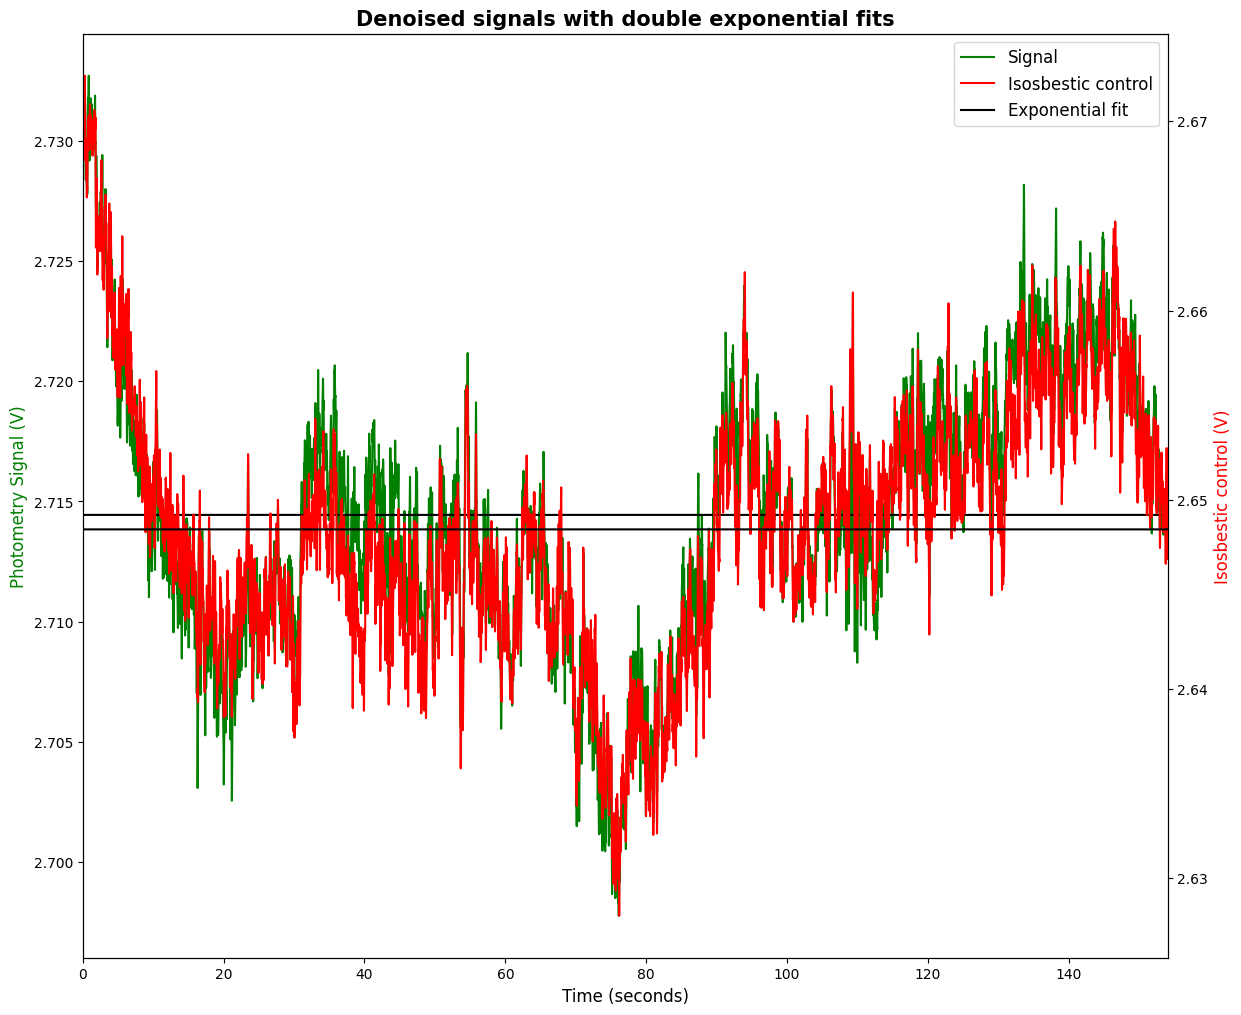

In [10]:
# The double exponential curve we are going to fit.
def double_exponential(t, const, amp_fast, amp_slow, tau_slow, tau_multiplier):
    '''Compute a double exponential function with constant offset.
    Parameters:
    t       : Time vector in seconds.
    const   : Amplitude of the constant offset. 
    amp_fast: Amplitude of the fast component.  
    amp_slow: Amplitude of the slow component.  
    tau_slow: Time constant of slow component in seconds.
    tau_multiplier: Time constant of fast component relative to slow. 
    '''
    tau_fast = tau_slow*tau_multiplier
    return const+amp_slow*np.exp(-t/tau_slow)+amp_fast*np.exp(-t/tau_fast)

# Fit curve to photometry signal.
max_sig = np.max(signal_denoised)
inital_params = [max_sig/2, max_sig/4, max_sig/4, 3600, 0.1]
bounds = ([0      , 0      , 0      , 600  , 0],
          [max_sig, max_sig, max_sig, 36000, 1])
signal_parms, parm_cov = curve_fit(double_exponential, time_seconds, signal_denoised, 
                                  p0=inital_params, bounds=bounds, maxfev=1000)
signal_expfit = double_exponential(time_seconds, *signal_parms)

# Fit curve to background signal.
max_sig = np.max(background_denoised)
inital_params = [max_sig/2, max_sig/4, max_sig/4, 3600, 0.1]
bounds = ([0      , 0      , 0      , 600  , 0],
          [max_sig, max_sig, max_sig, 36000, 1])
background_parms, parm_cov = curve_fit(double_exponential, time_seconds, background_denoised, 
                                  p0=inital_params, bounds=bounds, maxfev=1000)
background_expfit = double_exponential(time_seconds, *background_parms)

#plot fits over denoised data
fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_denoised, 'g', label='Signal')
plot3=ax1.plot(time_seconds, signal_expfit, color='k', linewidth=1.5, label='Exponential fit') 
ax2=plt.twinx()
plot2=ax2.plot(time_seconds, background_denoised, color='r', label='Isosbestic control') 
plot4=ax2.plot(time_seconds, background_expfit,color='k', linewidth=1.5) 


ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Denoised signals with double exponential fits')

lines = plot1 + plot2 + plot3
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right'); 
#ax1.set_ylim(0.24, 0.32)
#ax2.set_ylim(0.24, 0.32);


Inspect the fitted baselines for this recording before interpreting them as bleaching. Now subtract each fitted baseline from its corresponding channel.

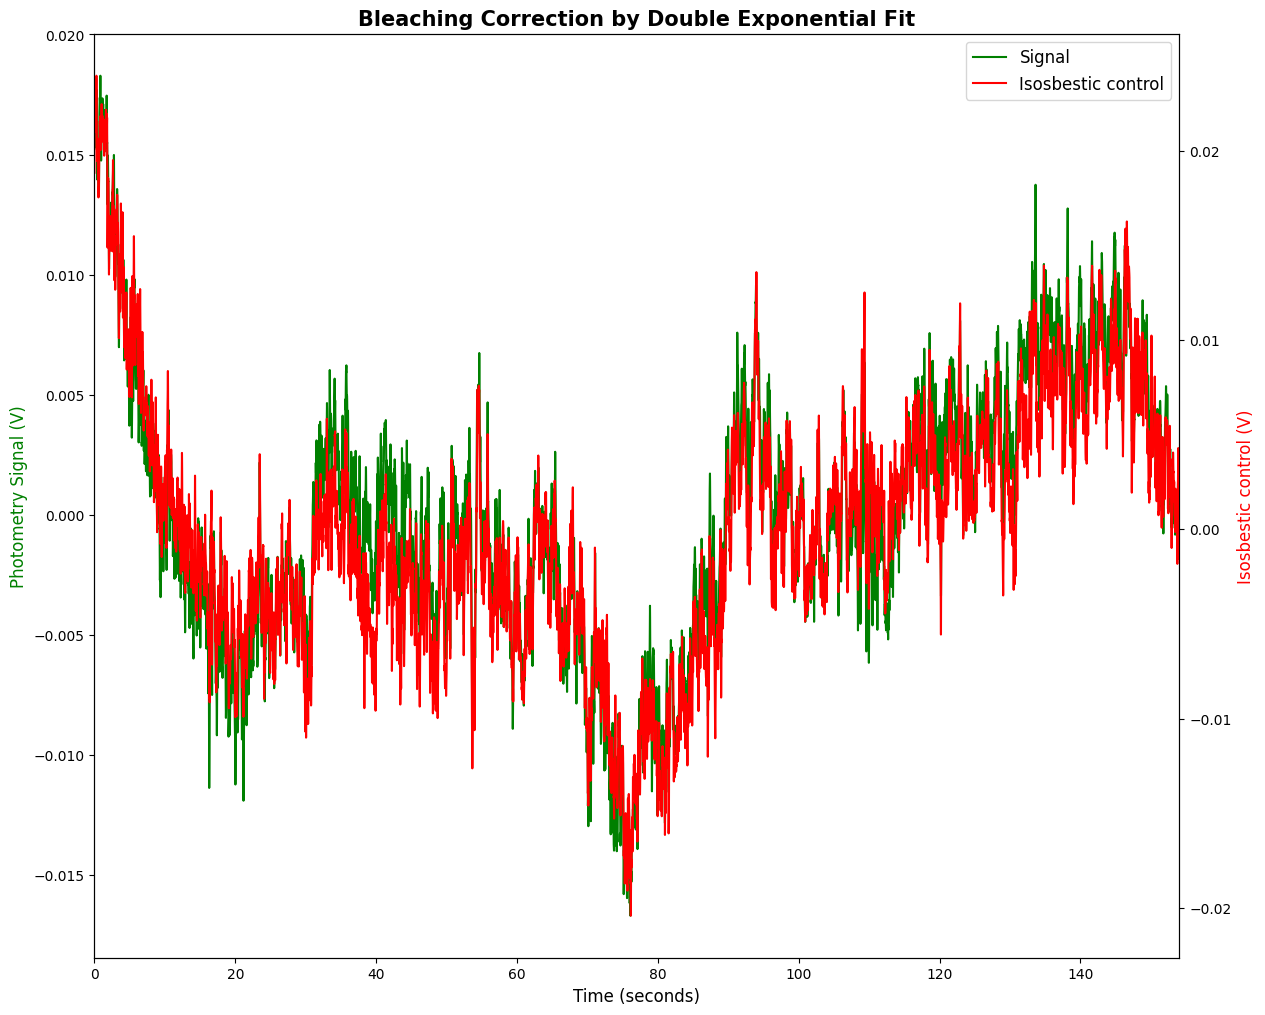

In [11]:
signal_detrended = signal_denoised - signal_expfit
background_detrended = background_denoised - background_expfit

fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_detrended, 'g', label='Signal')
ax2=plt.twinx()
plot2=ax2.plot(time_seconds, background_detrended, color='r', label='Isosbestic control') 

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Bleaching Correction by Double Exponential Fit')

lines = plot1+plot2 
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right'); 
#ax1.set_ylim(-0.18, 0.12)
#ax2.set_ylim(-0.1, 0.2);


### Method 2: High Pass Filter
A simpler way to remove slow changes is simply to highpass filter the signal with a very low cutoff frequency. Here we will high pass at 0.001Hz, which correponds to a period of 16 minutes.  All components of the signal changing on a slower timescale than this will be removed, which removes the drift due to bleaching, but will also remove any physiological variation in the signal on very slow timescales.


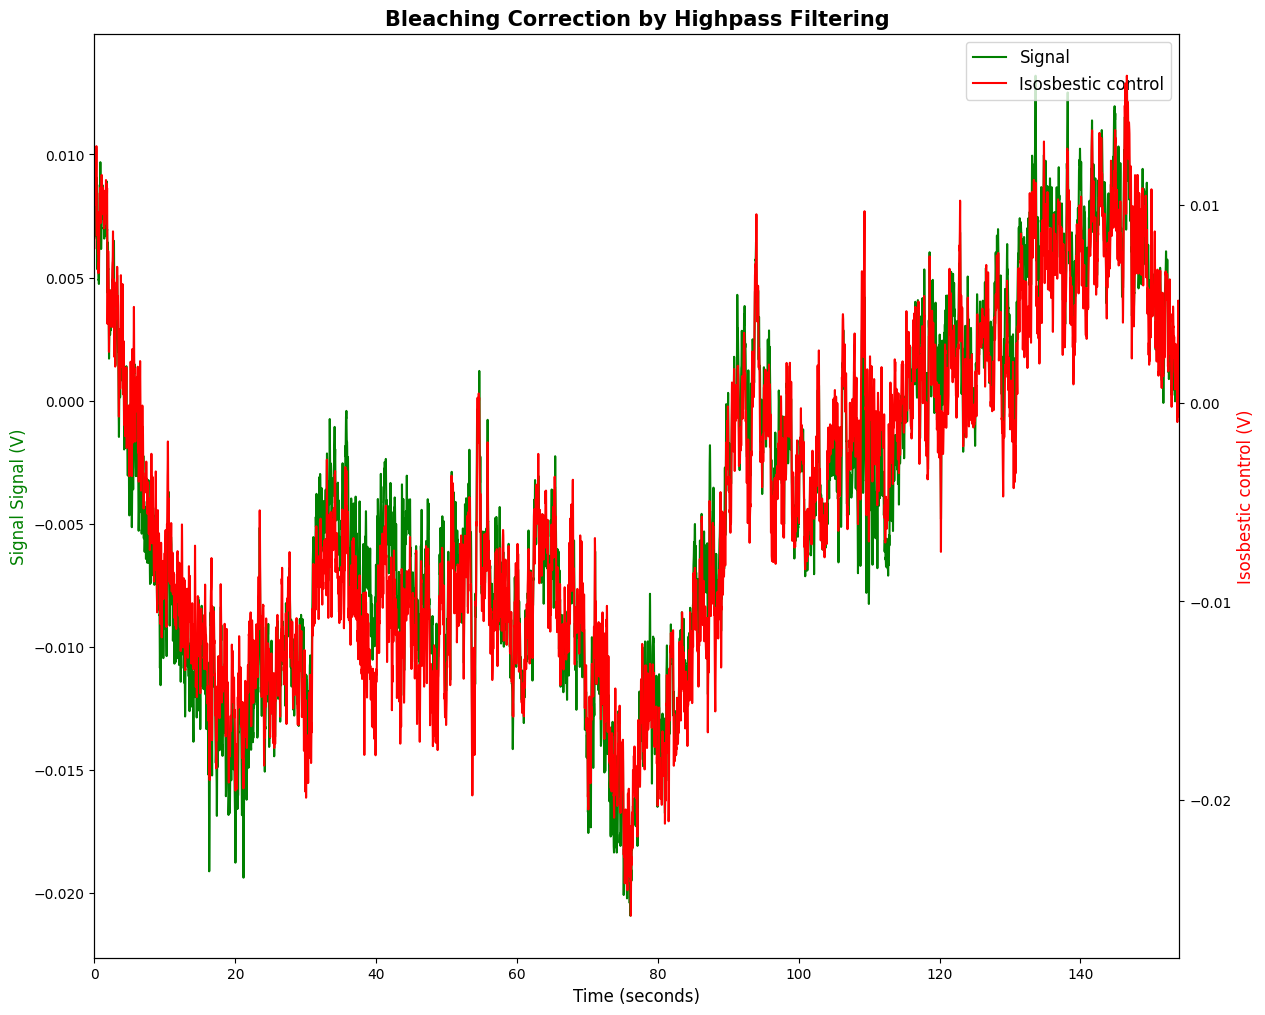

In [12]:
b,a = butter(2, 0.001, btype='high', fs=sampling_rate)
signal_highpass = filtfilt(b,a, signal_denoised, padtype='even')
background_highpass = filtfilt(b,a, background_denoised, padtype='even')


fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_highpass, 'g', label='Signal')
ax2=plt.twinx()
plot2=ax2.plot(time_seconds, background_highpass, color='r', label='Isosbestic control') 

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Signal Signal (V)', color='g')
ax2.set_ylabel('Isosbestic control (V)', color='r')
ax1.set_title('Bleaching Correction by Highpass Filtering')

lines = plot1+plot2 
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right'); 
#ax1.set_ylim(-0.18, 0.12)
#ax2.set_ylim(-0.1, 0.2);


# Motion correction

Fit the detrended isosbestic control to the detrended signal and subtract the fitted shared component. We use the double-exponential detrending path here. Check whether the control captures artifacts in this recording before interpreting the corrected signal.

Slope    : 0.789
R-squared: 0.906


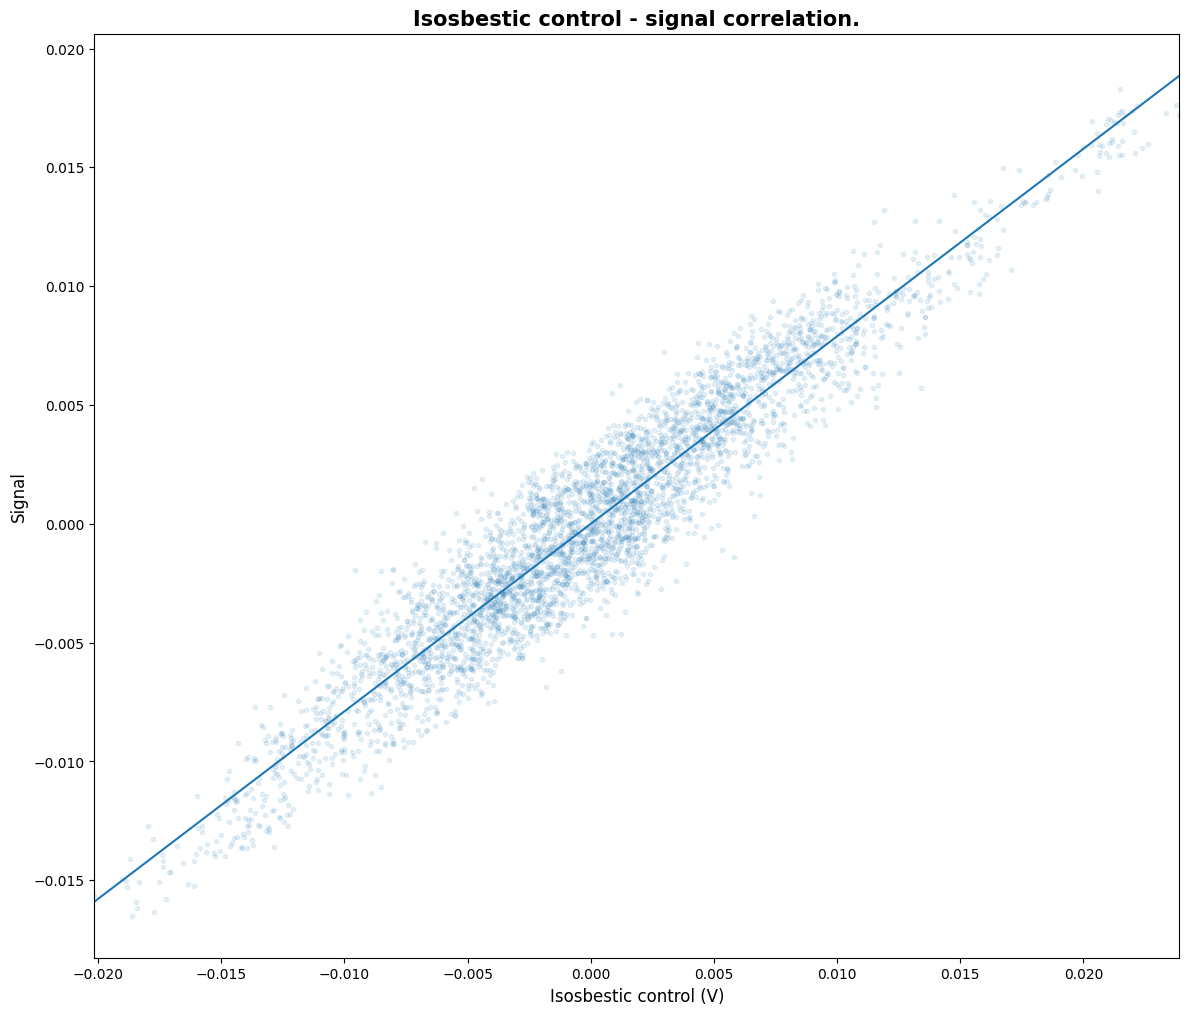

In [13]:
slope, intercept, r_value, p_value, std_err = linregress(x=background_detrended, y=signal_detrended)

plt.scatter(background_detrended[::5], signal_detrended[::5],alpha=0.1, marker='.')
x = np.array(plt.xlim())
plt.plot(x, intercept+slope*x)
plt.xlabel('Isosbestic control (V)')
plt.ylabel('Signal')
plt.title('Isosbestic control - signal correlation.')

print('Slope    : {:.3f}'.format(slope))
print('R-squared: {:.3f}'.format(r_value**2))

The slope and R-squared above are computed for the current recording. The slope scales control-channel fluctuations into signal-channel volts; R-squared reports their linear association after detrending. Neither alone establishes that the shared variation is exclusively movement.

Subtract the fitted control contribution from the signal.

(100.0, 154.05384615384617)

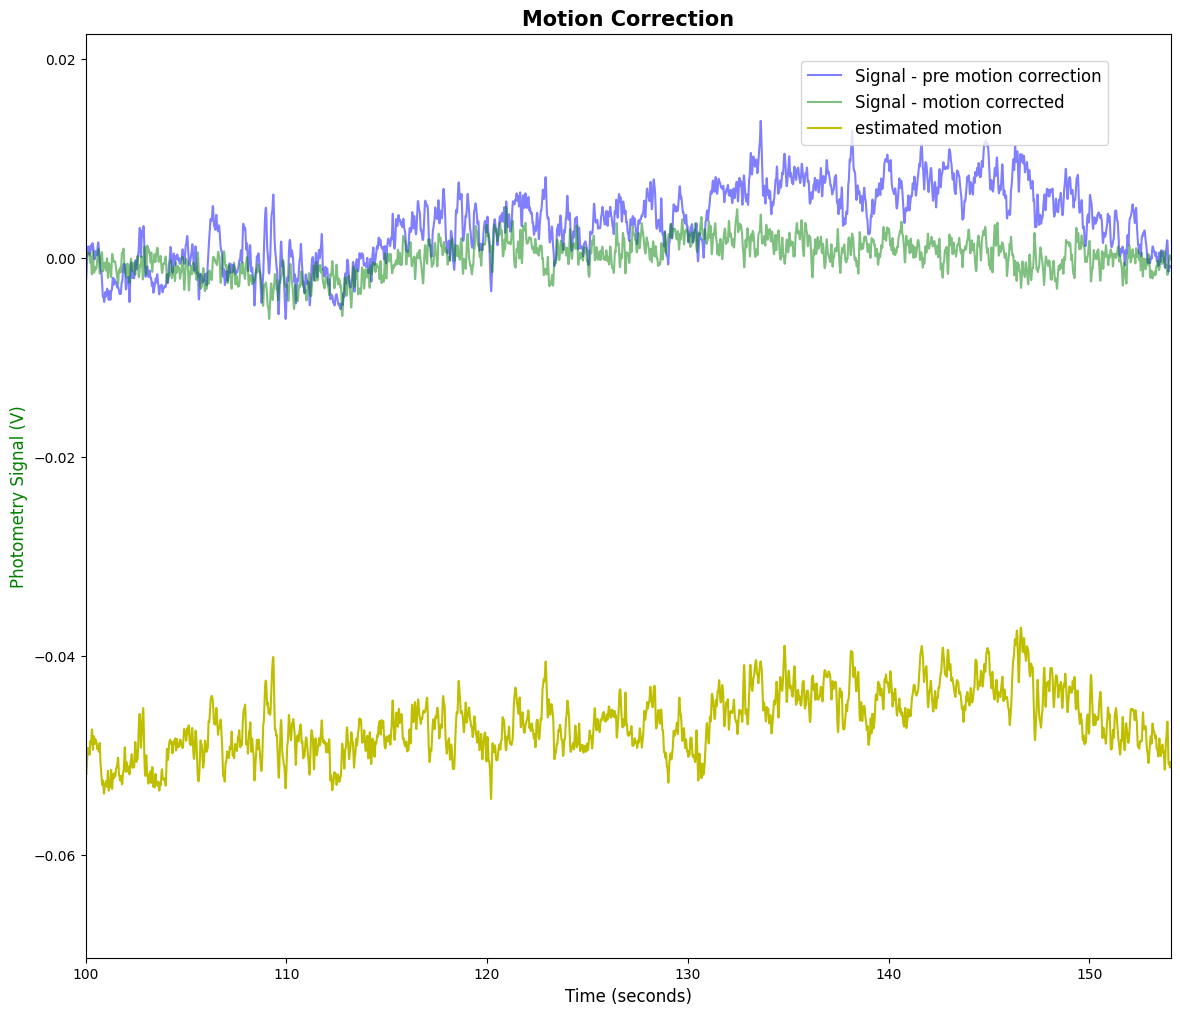

In [14]:
signal_est_motion = intercept + slope * background_detrended
signal_corrected = signal_detrended - signal_est_motion

fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_detrended, 'b' , label='Signal - pre motion correction', alpha=0.5)
plot3=ax1.plot(time_seconds, signal_corrected, 'g', label='Signal - motion corrected', alpha=0.5)
plot4=ax1.plot(time_seconds, signal_est_motion - 0.05, 'y', label='estimated motion')

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Photometry Signal (V)', color='g')
ax1.set_title('Motion Correction')

lines = plot1+plot3+plot4
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.95, 0.98))

ax1.set_xlim(100, min(160, time_seconds[-1]))  # 60 sec window
# ax1.set_ylim(-0.075, 0.075);

# Normalisation

Typically in a photometry experiment we want to combine data across sessions and/or subjects.  This is complicated by the fact that different sessions may have different levels of fluorphore expression, excitation light and autofluorescence.  It is therefore desirable to normalise the data to reduce this variability.  The two most widely used ways of doing this are computing dF/F or z-scores.

### Method 1: dF/F

To compute dF/F we divide the signal changes (dF) by the baseline fluorescence (F) and multiply by 100 to convert to percent. The dF is just the motion corrected signal plotted above.  The baseline fluorescence F changes over the course of the session due to photobleaching, and is just the baseline we estimated with our double exponential fit.

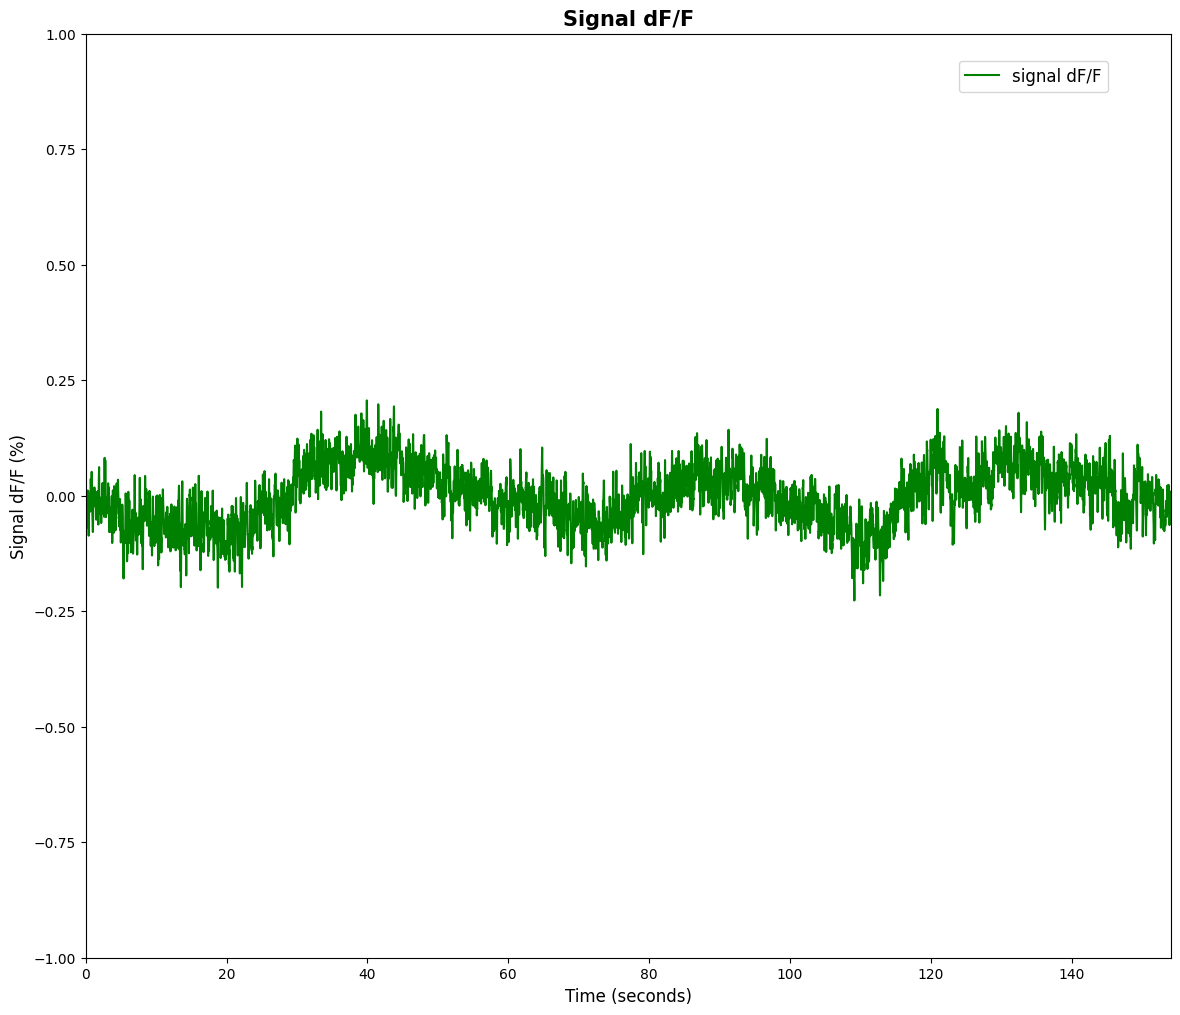

In [15]:
signal_dF_F = 100*signal_corrected/signal_expfit

fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_dF_F, 'g', label='signal dF/F')

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Signal dF/F (%)')
ax1.set_title('Signal dF/F')

lines = plot1
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.95, 0.98))

# ax1.set_xlim(100, min(210, time_seconds[-1]))
ax1.set_ylim(-1, 1);

### Method 2: Z-scoring

Alternatively, we can normalise the data by z-scoring each session - i.e. subtracting the mean and dividing by the standard deviation.

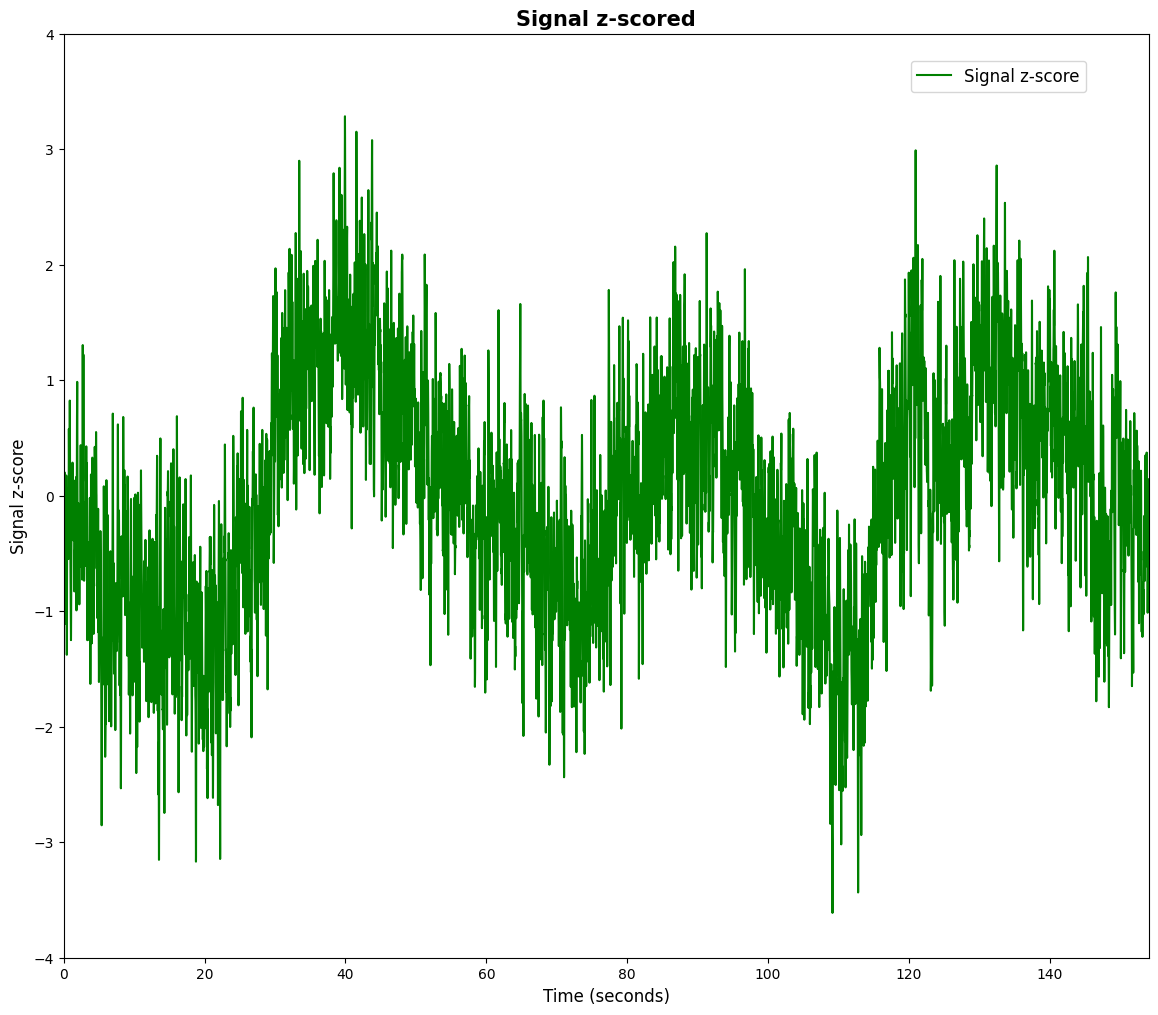

In [16]:
signal_zscored = (signal_corrected-np.mean(signal_corrected))/np.std(signal_corrected)


fig,ax1=plt.subplots()  
plot1=ax1.plot(time_seconds, signal_zscored, 'g', label='Signal z-score')

ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Signal z-score')
ax1.set_title('Signal z-scored')

lines = plot1
labels = [l.get_label() for l in lines]  
legend = ax1.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.95, 0.98))

# ax1.set_xlim(100, 130)
ax1.set_ylim(-4, 4);



# Airpuff-aligned response

Read `behavior_data_filename` from `data_folder` and select only `variable / user_set` rows whose JSON content contains `"airpuff": true`. Repeated true commands are separate events; run-start and run-end variable snapshots are excluded. Zero is the **logged user-set command**, not a measured valve-opening time.

Behavior TSV timestamps are in seconds. Match the behavior `rsync` events to photometry digital-1 rising edges, verify their interval pattern, and interpolate between matching pulses to convert behavior times to the photometry clock. This avoids relying on the files' wall-clock timestamps. The alignment deliberately stops if pulses are missing or mismatched rather than silently pairing the wrong events.

The two panels compare the existing motion-corrected **ΔF/F** and **session z-score** over the same events and time window (default −5 to +10 s). Lines show the mean and shading shows ±1 sample standard deviation across events (`ddof=1`), not the standard error. No per-event baseline subtraction or event-wise z-scoring is applied. Only complete windows within the recording and synchronization coverage are included. Windows can overlap when commands are close together.

ΔF/F divides the corrected fluorescence by the fitted, time-varying fluorescence baseline and expresses it as a percentage. The session z-score subtracts the full-session mean of the corrected fluorescence and divides by its full-session standard deviation. Thus ΔF/F describes relative fluorescence changes, while z-score describes changes relative to session variability; their numerical amplitudes are in different units. Similar shapes are expected when the fitted fluorescence baseline changes little over the event windows. The earlier LED-off subtraction and photobleaching/motion correction remain part of preprocessing.


In [17]:
import csv

behavior_data_path = os.path.join(data_folder, behavior_data_filename)
with open(behavior_data_path, newline='', encoding='utf-8-sig') as behavior_file:
    behavior_rows = list(csv.DictReader(behavior_file, delimiter='\t'))

behavior_subjects = {row['content'] for row in behavior_rows
                     if row['type'] == 'info' and row['subtype'] == 'subject_id'}
if behavior_subjects != {data['subject_ID']}:
    raise ValueError('Behavior and photometry subject IDs do not match.')

# Count each user-set command, even if the previous command was also True.
airpuff_behavior_times = np.array([
    float(row['time']) for row in behavior_rows
    if row['type'] == 'variable' and row['subtype'] == 'user_set'
    and json.loads(row['content']).get('airpuff') is True
])
behavior_sync_times = np.array([
    float(row['time']) for row in behavior_rows
    if row['type'] == 'event' and row['content'] == 'rsync'
])
photometry_sync_times = data['pulse_times_1'] / 1000


def validate_sync_pairs(behavior_sync, photometry_sync, sampling_rate):
    """Require a complete, ordered, one-to-one pulse train with matching intervals."""
    if len(behavior_sync) < 3 or len(behavior_sync) != len(photometry_sync):
        raise ValueError(
            f'Cannot pair sync pulses safely: {len(behavior_sync)} behavior vs '
            f'{len(photometry_sync)} photometry pulses. Check digital input 1 '
            'and use partial-pulse alignment if either recording missed pulses.'
        )
    if np.any(np.diff(behavior_sync) <= 0) or np.any(np.diff(photometry_sync) <= 0):
        raise ValueError('Sync pulses must be strictly increasing.')
    clock_scale, clock_offset = np.polyfit(behavior_sync, photometry_sync, 1)
    residuals = photometry_sync - (clock_scale * behavior_sync + clock_offset)
    interval_errors = np.diff(photometry_sync) - clock_scale * np.diff(behavior_sync)
    tolerance = max(2 / sampling_rate, 0.002)  # Two photometry samples or 2 ms.
    if (abs(clock_scale - 1) > 0.001 or np.max(np.abs(residuals)) > tolerance
            or np.max(np.abs(interval_errors)) > tolerance):
        raise ValueError('Sync interval patterns do not match within tolerance; '
                         'check that these files belong to the same session.')
    return clock_scale, clock_offset, residuals


clock_scale, clock_offset, sync_residuals = validate_sync_pairs(
    behavior_sync_times, photometry_sync_times, sampling_rate
)
# No extrapolation beyond the shared synchronization coverage.
airpuff_photometry_times = np.interp(
    airpuff_behavior_times, behavior_sync_times, photometry_sync_times,
    left=np.nan, right=np.nan
)
print(f'Matched {len(behavior_sync_times)} sync pulses; fitted offset '
      f'{clock_offset:.3f} s; maximum residual '
      f'{1000 * np.max(np.abs(sync_residuals)):.2f} ms.')
print(f'Found {len(airpuff_behavior_times)} airpuff=True user-set commands.')
for event_index, (behavior_t, photometry_t) in enumerate(
        zip(airpuff_behavior_times, airpuff_photometry_times), start=1):
    print(f'  Event {event_index}: behavior {behavior_t:.3f} s '
          f'-> photometry {photometry_t:.3f} s')


Matched 30 sync pulses; fitted offset 3.229 s; maximum residual 4.27 ms.
Found 4 airpuff=True user-set commands.
  Event 1: behavior 26.674 s -> photometry 29.906 s
  Event 2: behavior 35.421 s -> photometry 38.650 s
  Event 3: behavior 117.132 s -> photometry 120.363 s
  Event 4: behavior 125.918 s -> photometry 129.149 s


Plotting 4 of 4 events; 0 excluded for incomplete recording/sync coverage.
No per-event baseline subtraction. Shading shows ±1 sample SD across events.
Some event windows overlap; responses may include neighboring commands.


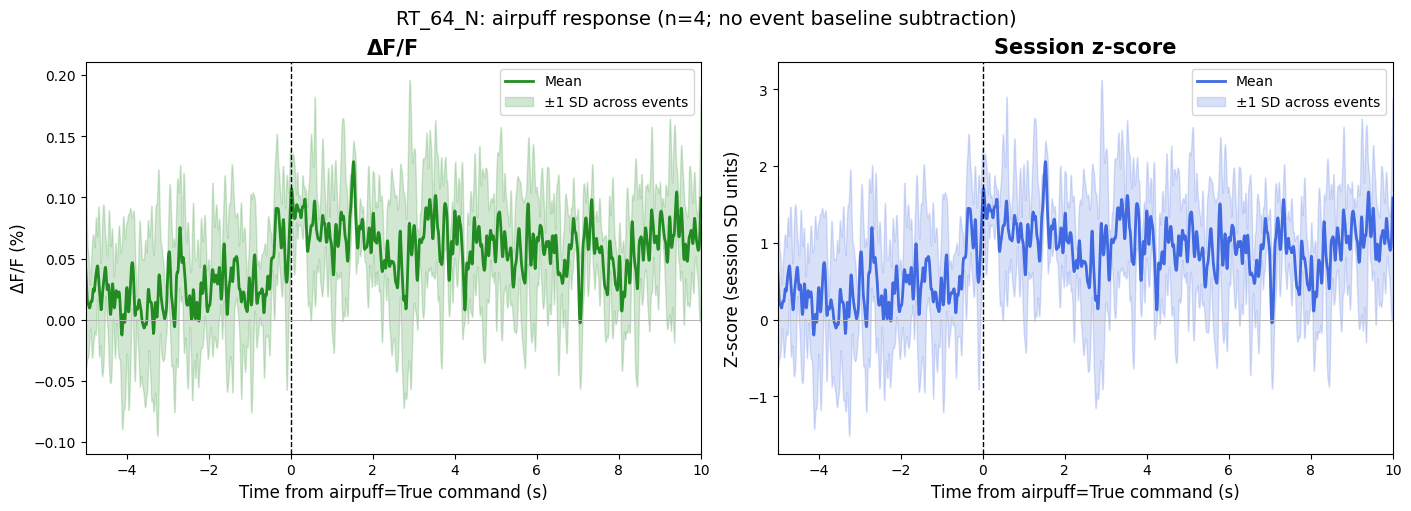

In [18]:
# Compare existing session-normalized signals without per-event baseline subtraction.
airpuff_window = (-5.0, 10.0)  # Seconds relative to the user-set command.

def extract_event_windows(times, values, events, window, fs, coverage):
    """Interpolate complete windows only; never pad or extrapolate edge events."""
    if not window[0] < 0 < window[1]:
        raise ValueError('The event window must span zero.')
    relative_times = np.arange(round(window[0] * fs), round(window[1] * fs) + 1) / fs
    lower = max(times[0], coverage[0])
    upper = min(times[-1], coverage[1])
    keep = (np.isfinite(events) & (events + relative_times[0] >= lower)
            & (events + relative_times[-1] <= upper))
    trials = np.array([np.interp(event + relative_times, times, values)
                       for event in events[keep]])
    return relative_times, trials.reshape((-1, len(relative_times))), keep

# Use the same events and time grid for both normalization methods.
airpuff_relative_time, airpuff_dff_trials, airpuff_keep = extract_event_windows(
    time_seconds, signal_dF_F, airpuff_photometry_times,
    airpuff_window, sampling_rate,
    (photometry_sync_times[0], photometry_sync_times[-1])
)
z_relative_time, airpuff_zscore_trials, z_keep = extract_event_windows(
    time_seconds, signal_zscored, airpuff_photometry_times,
    airpuff_window, sampling_rate,
    (photometry_sync_times[0], photometry_sync_times[-1])
)
assert np.array_equal(airpuff_keep, z_keep)
assert np.array_equal(airpuff_relative_time, z_relative_time)
airpuff_event_numbers = np.flatnonzero(airpuff_keep) + 1
n_airpuff_events = int(airpuff_keep.sum())
print(f'Plotting {n_airpuff_events} of {len(airpuff_keep)} events; '
      f'{(~airpuff_keep).sum()} excluded for incomplete recording/sync coverage.')
print('No per-event baseline subtraction. Shading shows ±1 sample SD across events.')

if n_airpuff_events == 0:
    print('No complete airpuff windows are available. Check the events and window settings.')
else:
    if np.any(np.diff(airpuff_photometry_times[airpuff_keep]) < np.ptp(airpuff_window)):
        print('Some event windows overlap; responses may include neighboring commands.')
    if n_airpuff_events == 1:
        print('Only one event: sample SD is undefined, so only the mean is shown.')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
    airpuff_summary = {}
    for ax, key, trials, title, units, color in zip(
        axes,
        ['dff', 'zscore'],
        [airpuff_dff_trials, airpuff_zscore_trials],
        ['ΔF/F', 'Session z-score'],
        ['ΔF/F (%)', 'Z-score (session SD units)'],
        ['forestgreen', 'royalblue']
    ):
        mean = trials.mean(axis=0)
        sd = trials.std(axis=0, ddof=1) if n_airpuff_events > 1 else np.full_like(mean, np.nan)
        airpuff_summary[key] = {'mean': mean, 'sd': sd}
        ax.plot(airpuff_relative_time, mean, color=color, lw=2, label='Mean')
        if n_airpuff_events > 1:
            ax.fill_between(airpuff_relative_time, mean - sd, mean + sd,
                            color=color, alpha=0.2, label='±1 SD across events')
        ax.axvline(0, color='black', ls='--', lw=1)
        ax.axhline(0, color='0.7', lw=0.7)
        ax.set(title=title, ylabel=units,
               xlabel='Time from airpuff=True command (s)', xlim=airpuff_window)
        ax.legend(fontsize=10)
    fig.suptitle(f"{data['subject_ID']}: airpuff response (n={n_airpuff_events}; no event baseline subtraction)",
                 fontsize=14)
    plt.show()


# Full-session ΔF/F and z-score with airpuff commands

Compare the complete motion-corrected session in the same units and colors as the event-aligned plots. Dashed vertical lines mark all `airpuff=True` user-set commands mapped onto the photometry clock using the sync pulses above, including commands excluded from event averages by window boundaries. No per-event baseline subtraction is applied. Commands outside synchronization coverage cannot be mapped and are reported below.


Marking 4 of 4 airpuff=True commands in the full session.


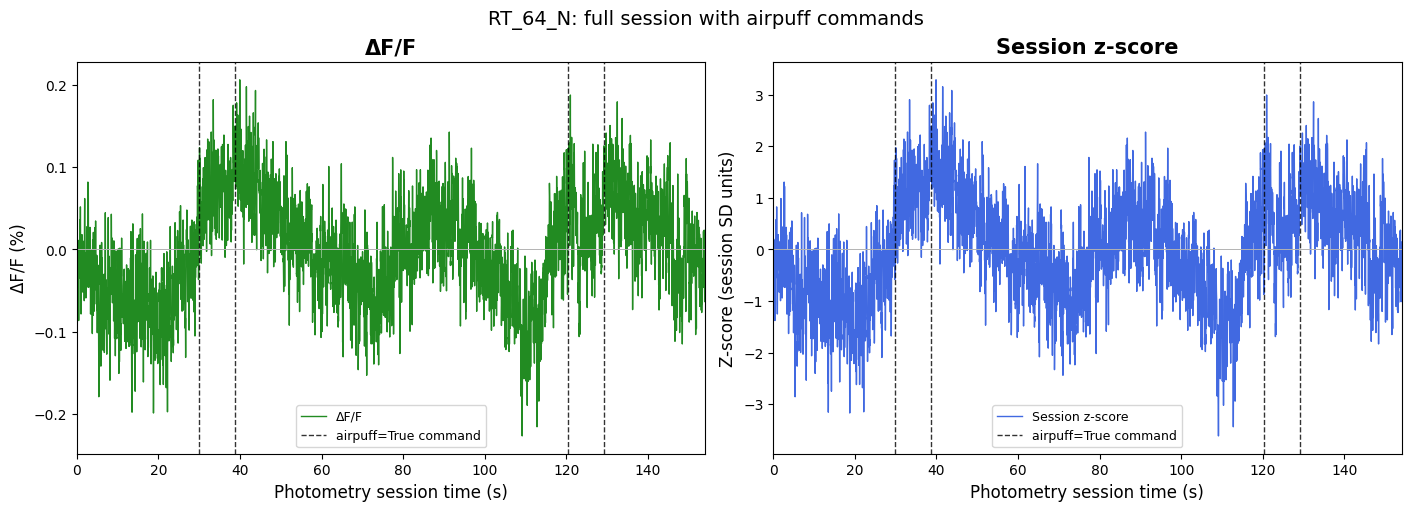

In [19]:
# Full-session comparison using the already synchronized command timestamps.
full_session_airpuff_mask = (
    np.isfinite(airpuff_photometry_times)
    & (airpuff_photometry_times >= time_seconds[0])
    & (airpuff_photometry_times <= time_seconds[-1])
)
full_session_airpuff_times = airpuff_photometry_times[full_session_airpuff_mask]
print(f'Marking {len(full_session_airpuff_times)} of {len(airpuff_photometry_times)} '
      'airpuff=True commands in the full session.')
if not full_session_airpuff_mask.all():
    print('Unmapped or out-of-recording commands:',
          (np.flatnonzero(~full_session_airpuff_mask) + 1).tolist())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
for ax, values, title, units, color in zip(
    axes,
    [signal_dF_F, signal_zscored],
    ['ΔF/F', 'Session z-score'],
    ['ΔF/F (%)', 'Z-score (session SD units)'],
    ['forestgreen', 'royalblue']
):
    ax.plot(time_seconds, values, color=color, lw=1, label=title)
    for event_index, event_time in enumerate(full_session_airpuff_times):
        ax.axvline(event_time, color='black', ls='--', lw=1, alpha=0.8,
                   label='airpuff=True command' if event_index == 0 else '_nolegend_')
    ax.axhline(0, color='0.7', lw=0.7)
    ax.set(title=title, ylabel=units, xlabel='Photometry session time (s)',
           xlim=(time_seconds[0], time_seconds[-1]))
    ax.legend(fontsize=9)
fig.suptitle(f"{data['subject_ID']}: full session with airpuff commands", fontsize=14)
plt.show()


# Airpuff comparison: 64N and 65LR

Each session is independently processed with the same 10 Hz lowpass filter, double-exponential bleaching fit, control regression, and normalization used above. Behavior commands are synchronized separately for each session. Both animals are overlaid on each panel using the existing `airpuff_window`, with **mean ±1 sample SD across each animal's events** and **no per-event baseline subtraction**. Z-scores use each animal's full-session corrected signal; events are not pooled across animals. The legend reports the number of complete event windows retained for each animal.


RT_64_N: 4/4 events; 30 sync pulses; max sync residual 4.27 ms.
  Some event windows overlap and may include neighboring commands.


RT_65_LR: 3/3 events; 18 sync pulses; max sync residual 3.45 ms.


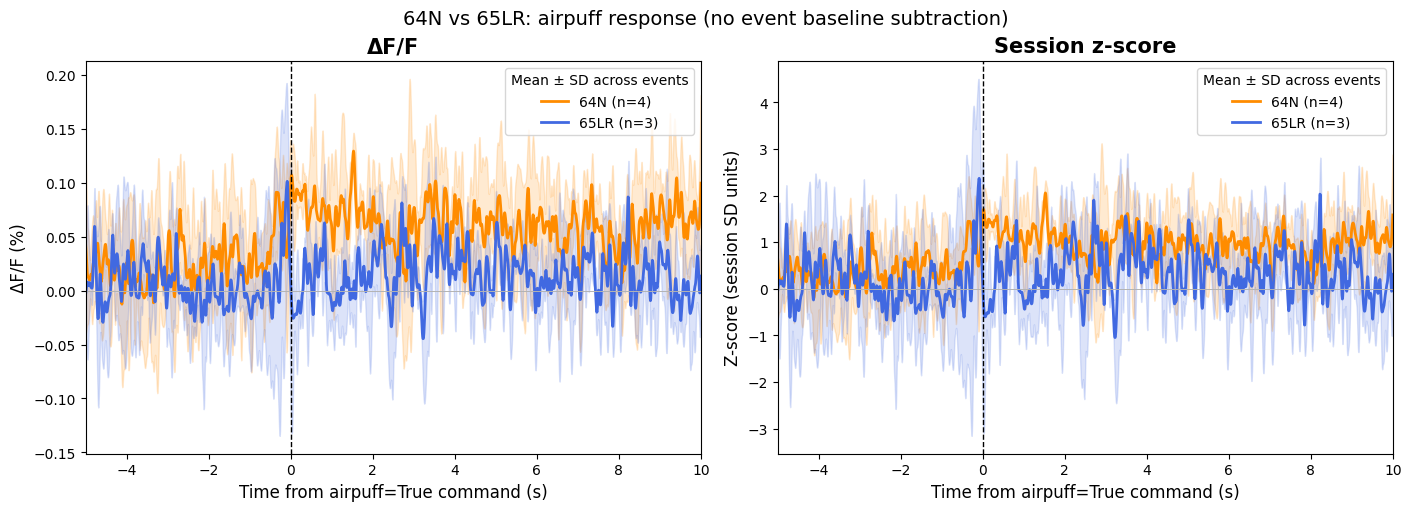

In [20]:
comparison_sessions = [
    ('64N', 'RT_64_N-2026-10-01-151306.ppd', 'RT_64_N-2026-10-01-151309.tsv'),
    ('65LR', 'RT_65_LR-2026-10-01-153922.ppd', 'RT_65_LR-2026-10-01-153924.tsv'),
]


def prepare_airpuff_comparison(ppd_filename, behavior_filename, window):
    """Independently process and synchronize one session, without changing earlier cells' data."""
    recording = import_ppd(os.path.join(data_folder, ppd_filename))
    fs = recording['sampling_rate']
    times = recording['time'] / 1000
    b, a = butter(2, 10, btype='low', fs=fs)
    signal = filtfilt(b, a, recording['analog_1'])
    control = filtfilt(b, a, recording['analog_2'])

    def fit_baseline(values):
        maximum = np.max(values)
        parameters, _ = curve_fit(
            double_exponential, times, values,
            p0=[maximum / 2, maximum / 4, maximum / 4, 3600, 0.1],
            bounds=([0, 0, 0, 600, 0], [maximum, maximum, maximum, 36000, 1]),
            maxfev=1000
        )
        return double_exponential(times, *parameters)

    baseline = fit_baseline(signal)
    detrended_signal = signal - baseline
    detrended_control = control - fit_baseline(control)
    fit = linregress(detrended_control, detrended_signal)
    corrected = detrended_signal - (fit.intercept + fit.slope * detrended_control)
    if np.any(baseline <= 0) or np.std(corrected) == 0:
        raise ValueError(f'{ppd_filename}: invalid baseline or zero signal variance.')
    normalized = {
        'dff': 100 * corrected / baseline,
        'zscore': (corrected - np.mean(corrected)) / np.std(corrected),
    }

    with open(os.path.join(data_folder, behavior_filename), newline='',
              encoding='utf-8-sig') as behavior_file:
        rows = list(csv.DictReader(behavior_file, delimiter='\t'))
    subjects = {row['content'] for row in rows
                if row['type'] == 'info' and row['subtype'] == 'subject_id'}
    if subjects != {recording['subject_ID']}:
        raise ValueError(f'{behavior_filename}: behavior/photometry subject mismatch.')
    behavior_sync = np.array([float(row['time']) for row in rows
                              if row['type'] == 'event' and row['content'] == 'rsync'])
    photo_sync = recording['pulse_times_1'] / 1000
    _, _, residuals = validate_sync_pairs(behavior_sync, photo_sync, fs)
    commands = np.array([float(row['time']) for row in rows
                         if row['type'] == 'variable' and row['subtype'] == 'user_set'
                         and json.loads(row['content']).get('airpuff') is True])
    events = np.interp(commands, behavior_sync, photo_sync, left=np.nan, right=np.nan)
    result = {'subject': recording['subject_ID'], 'normalized': normalized,
              'event_times': events, 'n_commands': len(commands), 'summary': {}}
    for key, values in normalized.items():
        relative_time, trials, keep = extract_event_windows(
            times, values, events, window, fs, (photo_sync[0], photo_sync[-1])
        )
        if len(trials) == 0:
            raise ValueError(f'{ppd_filename}: no complete airpuff windows for {window}.')
        result['summary'][key] = {
            'trials': trials,
            'mean': trials.mean(axis=0),
            'sd': trials.std(axis=0, ddof=1) if len(trials) > 1
                  else np.full(trials.shape[1], np.nan),
        }
        result.update(time=relative_time, keep=keep, n_events=int(keep.sum()))
    print(f"{recording['subject_ID']}: {result['n_events']}/{len(commands)} events; "
          f'{len(behavior_sync)} sync pulses; max sync residual '
          f'{1000 * np.max(np.abs(residuals)):.2f} ms.')
    if np.any(np.diff(events[keep]) < np.ptp(window)):
        print('  Some event windows overlap and may include neighboring commands.')
    if result['n_events'] == 1:
        print('  Only one event: sample SD is undefined; showing the mean only.')
    return result


comparison_results = {
    label: prepare_airpuff_comparison(ppd, behavior, airpuff_window)
    for label, ppd, behavior in comparison_sessions
}

# Check that the independent pipeline reproduces the currently selected session.
for result in comparison_results.values():
    if result['subject'] == data['subject_ID']:
        np.testing.assert_allclose(result['normalized']['dff'], signal_dF_F)
        np.testing.assert_allclose(result['normalized']['zscore'], signal_zscored)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
for label, color in [('64N', 'darkorange'), ('65LR', 'royalblue')]:
    result = comparison_results[label]
    for ax, key in zip(axes, ['dff', 'zscore']):
        summary = result['summary'][key]
        ax.plot(result['time'], summary['mean'], color=color, lw=2,
                label=f"{label} (n={result['n_events']})")
        if result['n_events'] > 1:
            ax.fill_between(result['time'], summary['mean'] - summary['sd'],
                            summary['mean'] + summary['sd'], color=color, alpha=0.18)
for ax, title, units in zip(axes, ['ΔF/F', 'Session z-score'],
                           ['ΔF/F (%)', 'Z-score (session SD units)']):
    ax.axvline(0, color='black', ls='--', lw=1)
    ax.axhline(0, color='0.7', lw=0.7)
    ax.set(title=title, ylabel=units, xlabel='Time from airpuff=True command (s)',
           xlim=airpuff_window)
    ax.legend(fontsize=10, title='Mean ± SD across events')
fig.suptitle('64N vs 65LR: airpuff response (no event baseline subtraction)', fontsize=14)
plt.show()


## Baseline-subtracted comparison

Subtract each event's own mean over **−2 ≤ time < 0 seconds**, separately for ΔF/F and session z-score, then recompute each animal's mean and sample SD across events. This uses the same events as the comparison above and preserves the original trials. The z-score panel remains in full-session SD units; no division by the pre-event SD is performed.


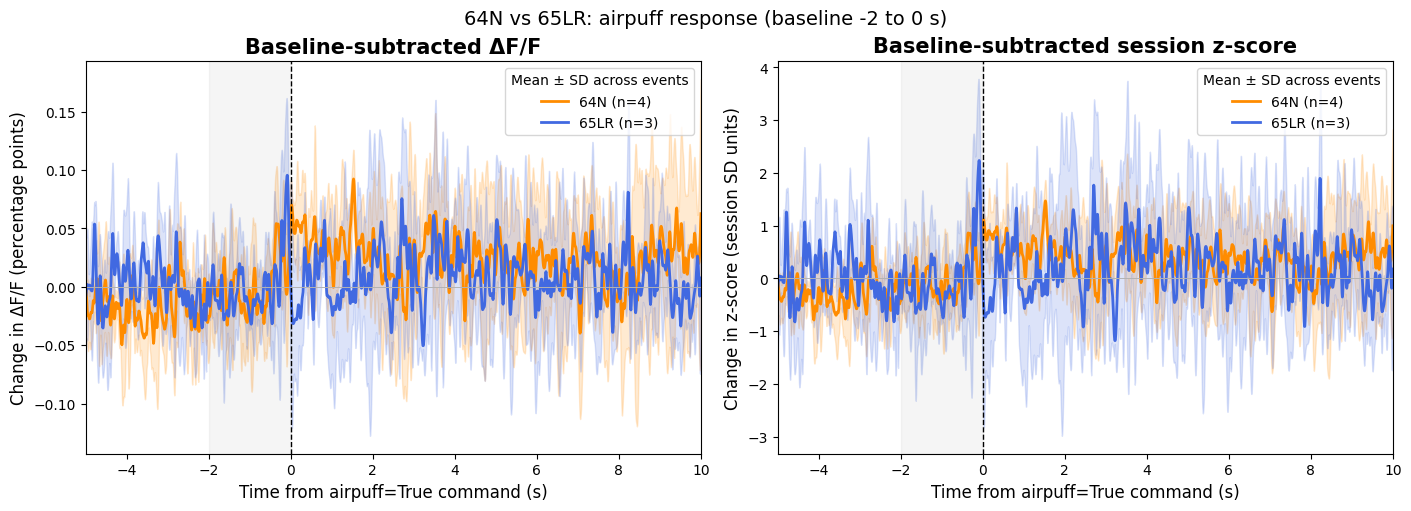

In [21]:
comparison_baseline_window = (-2.0, 0.0)  # Seconds; end excluded.
comparison_baseline_results = {}

for label, result in comparison_results.items():
    relative_time = result['time']
    baseline_start, baseline_end = comparison_baseline_window
    if not (relative_time[0] <= baseline_start < baseline_end <= 0
            and baseline_end <= relative_time[-1]):
        raise ValueError('Baseline window must be inside the pre-event time range.')
    baseline_mask = ((relative_time >= baseline_start) & (relative_time < baseline_end))
    if not baseline_mask.any():
        raise ValueError('Baseline window contains no samples.')
    comparison_baseline_results[label] = {}
    for key in ['dff', 'zscore']:
        trials = result['summary'][key]['trials']
        baseline_means = trials[:, baseline_mask].mean(axis=1, keepdims=True)
        centered_trials = trials - baseline_means
        np.testing.assert_allclose(centered_trials[:, baseline_mask].mean(axis=1),
                                   0, atol=1e-12)
        comparison_baseline_results[label][key] = {
            'trials': centered_trials,
            'mean': centered_trials.mean(axis=0),
            'sd': centered_trials.std(axis=0, ddof=1) if len(trials) > 1
                  else np.full(trials.shape[1], np.nan),
        }

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
for label, color in [('64N', 'darkorange'), ('65LR', 'royalblue')]:
    result = comparison_results[label]
    for ax, key in zip(axes, ['dff', 'zscore']):
        summary = comparison_baseline_results[label][key]
        ax.plot(result['time'], summary['mean'], color=color, lw=2,
                label=f"{label} (n={result['n_events']})")
        if result['n_events'] > 1:
            ax.fill_between(result['time'], summary['mean'] - summary['sd'],
                            summary['mean'] + summary['sd'], color=color, alpha=0.18)
for ax, title, units in zip(
    axes, ['Baseline-subtracted ΔF/F', 'Baseline-subtracted session z-score'],
    ['Change in ΔF/F (percentage points)', 'Change in z-score (session SD units)']
):
    ax.axvspan(*comparison_baseline_window, color='0.5', alpha=0.08)
    ax.axvline(0, color='black', ls='--', lw=1)
    ax.axhline(0, color='0.7', lw=0.7)
    ax.set(title=title, ylabel=units, xlabel='Time from airpuff=True command (s)',
           xlim=airpuff_window)
    ax.legend(fontsize=10, title='Mean ± SD across events')
fig.suptitle(
    f'64N vs 65LR: airpuff response (baseline {comparison_baseline_window[0]:g} to '
    f'{comparison_baseline_window[1]:g} s)', fontsize=14
)
plt.show()


# Fear-conditioning-method adaptation: airpuff comparison

Uses the supplied methods excerpt with the **green filter (10 Hz, Butterworth order 2)**. `prepare_airpuff_comparison` reruns that filter, double-exponential detrending, linear control regression, and `100 × corrected signal / bleaching fit` separately for each recording. We retain the notebook's zero-phase filtering, exponential-fit bounds, and synchronized command times because the excerpt does not specify alternatives.

Explicit choices for applying the excerpt to these airpuff recordings:

- Treat each `airpuff=True` user-set command as event zero. These are not identified TL, tone, or footshock trials.
- Interpret the 20 s TL baseline as subtracting each trial's mean ΔF/F over **[−20, 0) s** for the ΔF/F panel. The bleaching fit remains the F0 denominator. This interpretation is configurable below.
- Compute trial z-scores from **unsmoothed ΔF/F**, subtracting its **[−15, 0) s** mean and dividing by its sample SD (`ddof=1`, MATLAB convention). This replaces session z-scoring.
- Require the full 20 s baseline and post-event window for both panels, so the same trials enter each. Exclude incomplete or zero-variance trials and report their original event numbers. Retain and flag baselines containing another airpuff.
- Apply an **80-sample moving mean** at the native sampling rate after trial normalization, then average per mouse. Smoothing and averaging commute for the retained complete trials; shading is SEM across the smoothed trials (sample SD divided by the square root of the number of retained events). The centered even window and shortened endpoints follow [MATLAB movmean](https://www.mathworks.com/help/matlab/ref/movmean.html). At 130 Hz, 80 samples span approximately 0.615 s; centered smoothing can spread a response slightly before zero.
- Overlay each mouse's mean ± SEM. The equal-mouse mean is retained for numerical summaries but is not drawn. Peak and signed trapezoidal AUC are computed on smoothed mean-trial z-score traces over **0–10 s after airpuff**, a configurable analysis interval, not an inferred tone/footshock duration. These descriptive values use only the retained trials.


RT_64_N: 4/4 events; 30 sync pulses; max sync residual 4.27 ms.
  Some event windows overlap and may include neighboring commands.
64N: retained events [1, 2, 3, 4]; excluded events [].
  80-point smoothing duration: 0.615 s.


RT_65_LR: 3/3 events; 18 sync pulses; max sync residual 3.45 ms.
65LR: retained events [1, 2, 3]; excluded events [].
  80-point smoothing duration: 0.615 s.


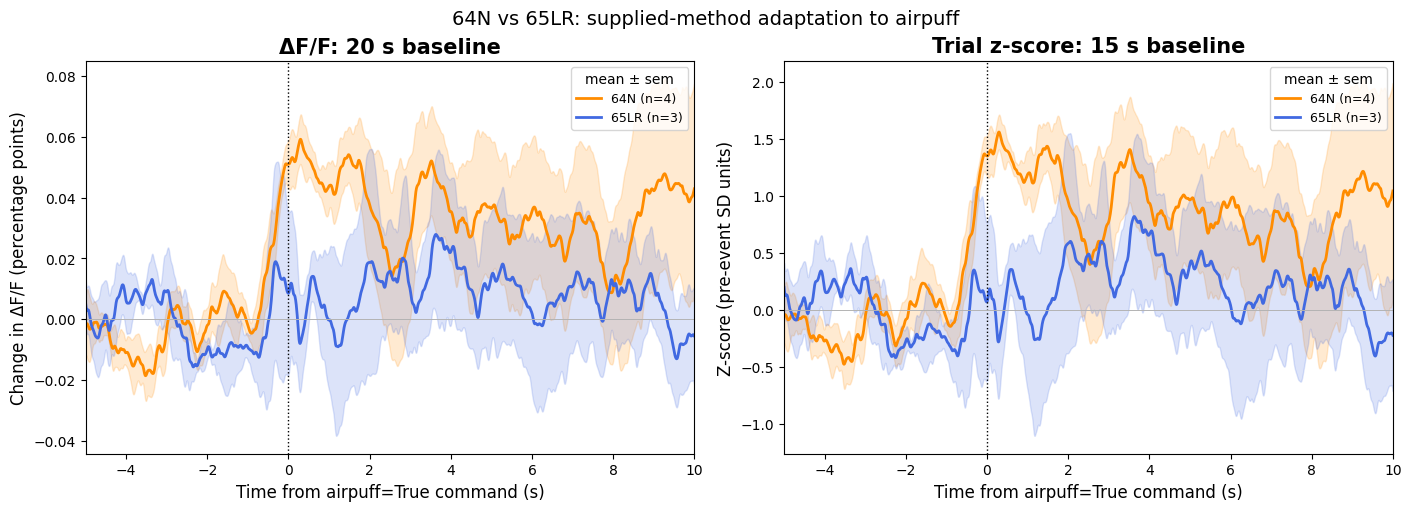

Airpuff analysis interval: (0.0, 10.0) s (smoothed mean-trial z-score).
64N: peak z=1.559 at 0.292 s; signed AUC=9.193 z·s
65LR: peak z=0.819 at 3.631 s; signed AUC=2.094 z·s
Equal-mouse mean: peak z=1.055 at 3.569 s; signed AUC=5.644 z·s
Mean of per-mouse peaks: 1.1890515777615196
Mean of per-mouse AUCs: 5.643678760636026


In [22]:
# Settings for the supplied-method adaptation (green sensor).
fear_plot_window = airpuff_window
fear_dff_baseline = (-5.0, 0.0)
fear_z_baseline = (-5.0, 0.0)
fear_subtract_dff_baseline = True
fear_smoothing_points = 80
fear_metric_window = (0.0, 10.0)  # Airpuff analysis interval, not a tone/footshock period.


def matlab_moving_mean(values, points=80):
    """Centered moving mean on the last axis, matching MATLAB's shrinking endpoints."""
    values = np.asarray(values, dtype=float)
    if points < 1 or int(points) != points:
        raise ValueError('Moving-mean window must be a positive integer.')
    points = int(points)
    indices = np.arange(values.shape[-1])
    starts = np.maximum(0, indices - points // 2)
    stops = np.minimum(values.shape[-1], indices + (points - 1) // 2 + 1)
    sums = np.concatenate([np.zeros(values.shape[:-1] + (1,)),
                           np.cumsum(values, axis=-1)], axis=-1)
    return (sums[..., stops] - sums[..., starts]) / (stops - starts)


fear_results = {}
for label, ppd_filename, behavior_filename in comparison_sessions:
    extraction_window = (min(fear_plot_window[0], fear_dff_baseline[0], fear_z_baseline[0]),
                         max(fear_plot_window[1], fear_metric_window[1]))
    session = prepare_airpuff_comparison(ppd_filename, behavior_filename, extraction_window)
    t = session['time']
    trials = session['summary']['dff']['trials']  # Freshly processed, unsmoothed ΔF/F (%).
    event_numbers = np.flatnonzero(session['keep']) + 1
    baseline20 = (t >= fear_dff_baseline[0]) & (t < fear_dff_baseline[1])
    baseline15 = (t >= fear_z_baseline[0]) & (t < fear_z_baseline[1])
    if baseline20.sum() < 2 or baseline15.sum() < 2:
        raise ValueError('Baseline windows need at least two samples.')
    z_mean = trials[:, baseline15].mean(axis=1, keepdims=True)
    z_sd = trials[:, baseline15].std(axis=1, ddof=1, keepdims=True)
    valid = np.isfinite(trials).all(axis=1) & np.isfinite(z_sd[:, 0]) & (z_sd[:, 0] > 0)
    excluded = sorted(set(range(1, session['n_commands'] + 1)) - set(event_numbers[valid]))
    trials, z_mean, z_sd = trials[valid], z_mean[valid], z_sd[valid]
    event_numbers = event_numbers[valid]
    if len(trials) == 0:
        raise ValueError(f'{label}: no usable trials after baseline checks.')
    dff_trials = (trials - trials[:, baseline20].mean(axis=1, keepdims=True)
                  if fear_subtract_dff_baseline else trials.copy())
    z_trials = (trials - z_mean) / z_sd
    # Verify trial normalization before smoothing.
    np.testing.assert_allclose(z_trials[:, baseline15].mean(axis=1), 0, atol=1e-12)
    np.testing.assert_allclose(z_trials[:, baseline15].std(axis=1, ddof=1), 1, atol=1e-12)
    if fear_subtract_dff_baseline:
        np.testing.assert_allclose(dff_trials[:, baseline20].mean(axis=1), 0, atol=1e-12)
    summary = {}
    for key, normalized_trials in [('dff', dff_trials), ('zscore', z_trials)]:
        smoothed = matlab_moving_mean(normalized_trials, fear_smoothing_points)
        summary[key] = {
            'trials_unsmoothed': normalized_trials, 'trials': smoothed,
            'mean': smoothed.mean(axis=0),
            'sem': smoothed.std(axis=0, ddof=1) / np.sqrt(len(smoothed)) if len(smoothed) > 1
                  else np.full(len(t), np.nan),
        }
    fear_results[label] = dict(time=t, n_events=len(trials), event_numbers=event_numbers,
                               excluded_event_numbers=excluded, summary=summary)
    baseline_overlaps = []
    all_events = session['event_times']
    for number in event_numbers:
        event_time = all_events[number - 1]
        if np.any((all_events >= event_time + fear_dff_baseline[0]) & (all_events < event_time)):
            baseline_overlaps.append(int(number))
    print(f'{label}: retained events {event_numbers.tolist()}; excluded events {excluded}.')
    if baseline_overlaps:
        print(f'  Earlier airpuff within the 20 s baseline for events {baseline_overlaps}.')
    print(f'  80-point smoothing duration: {fear_smoothing_points * np.median(np.diff(t)):.3f} s.')

# Equal-mouse cohort average: do not pool unequal numbers of trials.
fear_common_time = fear_results['64N']['time']
for result in fear_results.values():
    np.testing.assert_allclose(result['time'], fear_common_time)
fear_cohort = {
    key: np.mean([result['summary'][key]['mean'] for result in fear_results.values()], axis=0)
    for key in ['dff', 'zscore']
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
for label, color in [('64N', 'darkorange'), ('65LR', 'royalblue')]:
    result = fear_results[label]
    for ax, key in zip(axes, ['dff', 'zscore']):
        summary = result['summary'][key]
        ax.plot(result['time'], summary['mean'], color=color, lw=2,
                label=f"{label} (n={result['n_events']})")
        if result['n_events'] > 1:
            ax.fill_between(result['time'], summary['mean'] - summary['sem'],
                            summary['mean'] + summary['sem'], color=color, alpha=0.18)

for ax, key, title, units in zip(
    axes, ['dff', 'zscore'],
    ['ΔF/F: 20 s baseline' if fear_subtract_dff_baseline else 'ΔF/F',
     'Trial z-score: 15 s baseline'],
    ['Change in ΔF/F (percentage points)' if fear_subtract_dff_baseline else 'ΔF/F (%)',
     'Z-score (pre-event SD units)']
):
    # ax.plot(fear_common_time, fear_cohort[key], color='black', ls='--', lw=1.5, label='Equal-mouse mean (2 mice)')
    ax.axvline(0, color='black', ls=':', lw=1)
    ax.axhline(0, color='0.7', lw=0.7)
    ax.set(title=title, ylabel=units, xlabel='Time from airpuff=True command (s)',
           xlim=fear_plot_window)
    ax.legend(fontsize=9, title='mean ± sem')
fig.suptitle('64N vs 65LR: supplied-method adaptation to airpuff', fontsize=14)
plt.show()

# Descriptive peak and signed AUC on smoothed mean-trial z-score traces.
metric_mask = ((fear_common_time >= fear_metric_window[0])
               & (fear_common_time <= fear_metric_window[1]))
if metric_mask.sum() < 2 or not (
    fear_common_time[0] <= fear_metric_window[0] < fear_metric_window[1] <= fear_common_time[-1]
):
    raise ValueError('Metric window must be covered by the extracted time grid.')
from scipy.integrate import trapezoid
fear_metrics = {}
metric_traces = {label: result['summary']['zscore']['mean'] for label, result in fear_results.items()}
metric_traces['Equal-mouse mean'] = fear_cohort['zscore']
print(f'Airpuff analysis interval: {fear_metric_window} s (smoothed mean-trial z-score).')
for label, trace in metric_traces.items():
    segment = trace[metric_mask]
    metric_times = fear_common_time[metric_mask]
    peak_index = int(np.argmax(segment))
    fear_metrics[label] = dict(peak_z=float(segment[peak_index]),
                               peak_time_s=float(metric_times[peak_index]),
                               auc_z_s=float(trapezoid(segment, x=metric_times)))
    m = fear_metrics[label]
    print(f"{label}: peak z={m['peak_z']:.3f} at {m['peak_time_s']:.3f} s; "
          f"signed AUC={m['auc_z_s']:.3f} z·s")
# Peak of the cohort mean and mean of per-mouse peaks are different quantities.
print('Mean of per-mouse peaks:', np.mean([fear_metrics[label]['peak_z'] for label in fear_results]))
print('Mean of per-mouse AUCs:', np.mean([fear_metrics[label]['auc_z_s'] for label in fear_results]))


# Tri-exponential / slow-baseline motion correction

This independent pipeline follows the **pasted preprocessing description**: fit each raw channel with three nonnegative decaying exponentials plus a constant, compute `(raw − trend) / trend`, lowpass both channels' ΔF/F at **0.05 Hz**, regress the smoothed 405 nm baseline onto the smoothed functional baseline, subtract the fitted baseline from functional ΔF/F, then lowpass at **3 Hz**. Both filters are second-order Butterworth filters applied forward/backward using second-order sections. Motion regression here is ordinary least squares with an intercept. Channel assignments remain `analog_1` = functional and `analog_2` = isosbestic.

Reference inspected: [aind-fip-dff preprocessing at commit 6d49115](https://github.com/AllenNeuralDynamics/aind-fip-dff/blob/6d49115413d3d8d339760989a46c47293f7a0b55/code/utils/preprocess.py). **This is an implementation of the excerpt, not an exact run of the current repository.** The current repository prefilters its tri-exponential fitting target, uses initialization windows longer than these recordings, and its motion correction defaults to robust regression with subtraction of scaled unfiltered control. Here we fit the raw samples directly with bounded, scaled least squares and short-recording initial values, and subtract the fitted *lowpass baseline* as requested. Three decay components may be poorly distinguishable in these short, non-monotonic recordings; fitted trends and parameters are retained for inspection, not interpreted as biological timescales.

The final figure compares both animals with **mean ± SEM across retained events**. ΔF/F is displayed in percent without an additional event-baseline subtraction. The companion z-score is an **extra visualization step, not part of the excerpt**: normalize the new 3 Hz filtered ΔF/F by each event's pre-event mean and sample SD, using the current `fear_z_baseline` setting. There is no additional 80-point smoothing and no equal-mouse curve. Results and every intermediate trace are stored in `triexp_results`.


RT_64_N: events [1, 2, 3, 4]; excluded []; motion slope=0.818, baseline R²=0.932.
  Channel 1: trend fit RMSE=0.005243 V; decay time constants (s)=[1.000000e-02 3.820000e+00 1.540538e+04]
  Channel 2: trend fit RMSE=0.006080 V; decay time constants (s)=[4.63000e+00 4.63000e+00 1.10077e+04]


RT_65_LR: events [1, 2, 3]; excluded []; motion slope=0.708, baseline R²=0.938.
  Channel 1: trend fit RMSE=0.003480 V; decay time constants (s)=[3.12000e+00 3.39293e+03 4.62576e+03]
  Channel 2: trend fit RMSE=0.004532 V; decay time constants (s)=[3.50000e+00 8.79061e+03 9.58967e+03]


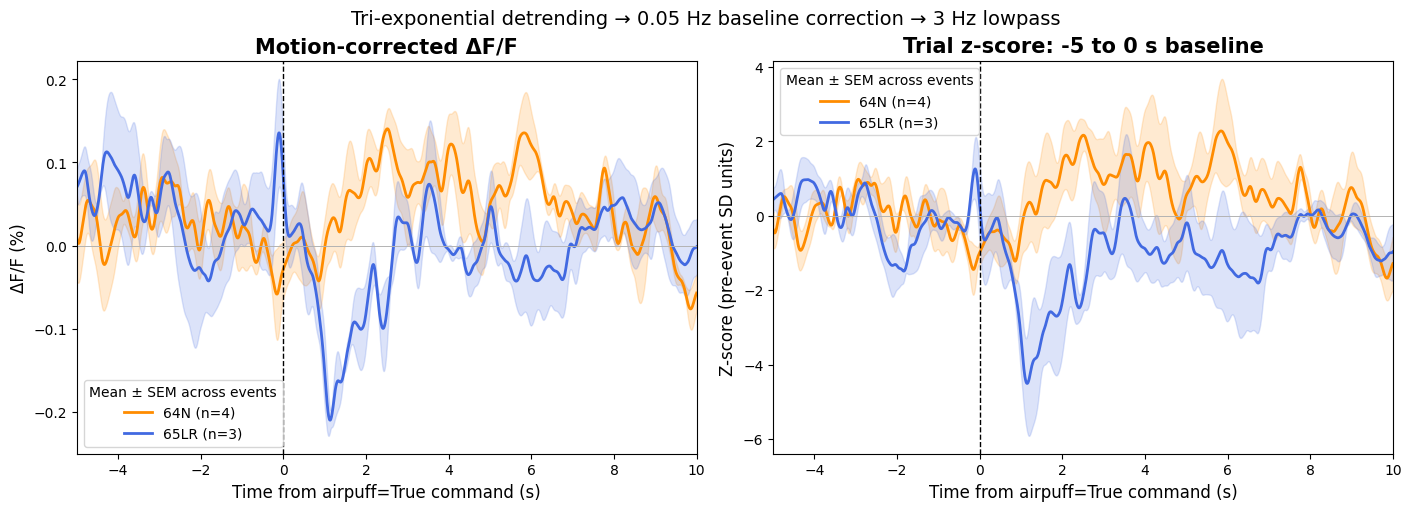

In [23]:
from scipy.optimize import least_squares
from scipy.signal import sosfiltfilt

triexp_event_window = airpuff_window
triexp_z_baseline = tuple(fear_z_baseline)  # Current pre-event window; separate from preprocessing.
triexp_motion_cutoff = 0.05
triexp_output_cutoff = 3.0


def fit_raw_triexponential(times, raw):
    """Fit raw samples directly: sum of three decays plus a constant; two starts."""
    duration = times[-1] - times[0]
    scale = float(np.median(raw))
    if duration <= 0 or scale <= 0 or not np.isfinite(raw).all():
        raise ValueError('Tri-exponential fitting requires finite data and a positive median.')
    x = (times - times[0]) / duration
    y = raw / scale
    min_tau = max(float(np.median(np.diff(x))), 1e-6)

    def model(parameters):
        amplitudes, taus, offset = parameters[:3], parameters[3:6], parameters[6]
        return np.exp(-x[:, None] / taus) @ amplitudes + offset

    def jacobian(parameters):
        amplitudes, taus = parameters[:3], parameters[3:6]
        decays = np.exp(-x[:, None] / taus)
        return np.column_stack((decays, decays * amplitudes * x[:, None] / taus**2,
                                np.ones(len(x))))

    decay_size = max(float(np.mean(y[:min(130, len(y))]) - np.mean(y[-min(130, len(y)):])), 0.003)
    candidates = []
    for taus in ([0.02, 0.2, 2.0], [0.05, 0.5, 5.0]):
        initial = np.r_[np.full(3, decay_size / 3), taus, max(0.01, np.median(y) - decay_size)]
        fit = least_squares(
            lambda parameters: model(parameters) - y, initial, jac=jacobian,
            bounds=(np.r_[np.zeros(3), np.full(3, min_tau), 0.0],
                    np.r_[np.full(3, np.inf), np.full(3, 100.0), np.inf]),
            x_scale='jac', max_nfev=2000, ftol=1e-8, xtol=1e-8, gtol=1e-8
        )
        if fit.success and np.isfinite(fit.cost):
            candidates.append(fit)
    if not candidates:
        raise RuntimeError('Tri-exponential fit did not converge; no fallback was applied.')
    best = min(candidates, key=lambda fit: fit.cost)
    trend = scale * model(best.x)
    if np.any(trend <= 0) or not np.isfinite(trend).all():
        raise ValueError('Invalid tri-exponential denominator.')
    order = np.argsort(best.x[3:6])
    diagnostics = {
        'amplitudes_V': scale * best.x[:3][order],
        'time_constants_s': duration * best.x[3:6][order],
        'offset_V': scale * best.x[6],
        'rmse_V': float(np.sqrt(np.mean((raw - trend)**2))),
        'nfev': best.nfev,
    }
    return trend, diagnostics


def preprocess_triexp_session(ppd_filename, behavior_filename):
    recording = import_ppd(os.path.join(data_folder, ppd_filename), low_pass=None, high_pass=None)
    fs = recording['sampling_rate']
    times = recording['time'] / 1000
    raw = np.stack([recording['analog_1'], recording['analog_2']])
    fits = [fit_raw_triexponential(times, channel) for channel in raw]
    trends = np.stack([fit[0] for fit in fits])
    dff = (raw - trends) / trends  # Fractional ΔF/F for both channels.
    motion_sos = butter(2, triexp_motion_cutoff, btype='low', fs=fs, output='sos')
    slow_baselines = sosfiltfilt(motion_sos, dff, axis=1)
    if np.std(slow_baselines[1]) <= np.finfo(float).eps:
        raise ValueError('Isosbestic baseline has insufficient variance for regression.')
    regression = linregress(slow_baselines[1], slow_baselines[0])
    estimated_motion = regression.intercept + regression.slope * slow_baselines[1]
    motion_corrected = dff[0] - estimated_motion
    output_sos = butter(2, triexp_output_cutoff, btype='low', fs=fs, output='sos')
    filtered_dff = sosfiltfilt(output_sos, motion_corrected)
    if not np.isfinite(filtered_dff).all():
        raise ValueError('Preprocessing produced non-finite values.')

    with open(os.path.join(data_folder, behavior_filename), newline='', encoding='utf-8-sig') as f:
        rows = list(csv.DictReader(f, delimiter='\t'))
    subjects = {row['content'] for row in rows
                if row['type'] == 'info' and row['subtype'] == 'subject_id'}
    if subjects != {recording['subject_ID']}:
        raise ValueError('Behavior and photometry subjects do not match.')
    behavior_sync = np.array([float(row['time']) for row in rows
                              if row['type'] == 'event' and row['content'] == 'rsync'])
    photo_sync = recording['pulse_times_1'] / 1000
    validate_sync_pairs(behavior_sync, photo_sync, fs)
    commands = np.array([float(row['time']) for row in rows
                         if row['type'] == 'variable' and row['subtype'] == 'user_set'
                         and json.loads(row['content']).get('airpuff') is True])
    event_times = np.interp(commands, behavior_sync, photo_sync, left=np.nan, right=np.nan)
    if not triexp_z_baseline[0] < triexp_z_baseline[1] <= 0:
        raise ValueError('Z-score baseline must be a nonempty pre-event interval.')
    window = (min(triexp_event_window[0], triexp_z_baseline[0]), triexp_event_window[1])
    relative_time, dff_trials, keep = extract_event_windows(
        times, 100 * filtered_dff, event_times, window, fs, (photo_sync[0], photo_sync[-1])
    )
    baseline_mask = ((relative_time >= triexp_z_baseline[0])
                     & (relative_time < triexp_z_baseline[1]))
    if baseline_mask.sum() < 2 or len(dff_trials) == 0:
        raise ValueError('No complete events or insufficient z-score baseline samples.')
    baseline_mean = dff_trials[:, baseline_mask].mean(axis=1, keepdims=True)
    baseline_sd = dff_trials[:, baseline_mask].std(axis=1, ddof=1, keepdims=True)
    valid = np.isfinite(baseline_sd[:, 0]) & (baseline_sd[:, 0] > 0)
    event_numbers = (np.flatnonzero(keep) + 1)[valid]
    dff_trials = dff_trials[valid]
    if len(dff_trials) == 0:
        raise ValueError('No events with nonzero baseline SD.')
    z_trials = (dff_trials - baseline_mean[valid]) / baseline_sd[valid]
    np.testing.assert_allclose(z_trials[:, baseline_mask].mean(axis=1), 0, atol=1e-12)
    np.testing.assert_allclose(z_trials[:, baseline_mask].std(axis=1, ddof=1), 1, atol=1e-12)
    summaries = {}
    for key, trials in [('dff', dff_trials), ('zscore', z_trials)]:
        summaries[key] = dict(trials=trials, mean=trials.mean(axis=0),
            sem=trials.std(axis=0, ddof=1) / np.sqrt(len(trials)) if len(trials) > 1
                else np.full(trials.shape[1], np.nan))
    excluded = sorted(set(range(1, len(commands) + 1)) - set(event_numbers))
    print(f"{recording['subject_ID']}: events {event_numbers.tolist()}; excluded {excluded}; "
          f'motion slope={regression.slope:.3f}, baseline R²={regression.rvalue**2:.3f}.')
    for index, (_, diagnostic) in enumerate(fits, start=1):
        print(f"  Channel {index}: trend fit RMSE={diagnostic['rmse_V']:.6f} V; "
              f"decay time constants (s)={np.round(diagnostic['time_constants_s'], 2)}")
    return dict(time=times, raw=raw, trends=trends, fit_diagnostics=[fit[1] for fit in fits],
                dff_fraction=dff, slow_baselines=slow_baselines, estimated_motion=estimated_motion,
                motion_corrected_fraction=motion_corrected, filtered_dff_percent=100 * filtered_dff,
                event_times=event_times, event_numbers=event_numbers, excluded_event_numbers=excluded,
                relative_time=relative_time, n_events=len(dff_trials), summary=summaries)


triexp_results = {
    label: preprocess_triexp_session(ppd_filename, behavior_filename)
    for label, ppd_filename, behavior_filename in comparison_sessions
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
for label, color in [('64N', 'darkorange'), ('65LR', 'royalblue')]:
    result = triexp_results[label]
    for ax, key in zip(axes, ['dff', 'zscore']):
        summary = result['summary'][key]
        ax.plot(result['relative_time'], summary['mean'], color=color, lw=2,
                label=f"{label} (n={result['n_events']})")
        if result['n_events'] > 1:
            ax.fill_between(result['relative_time'], summary['mean'] - summary['sem'],
                            summary['mean'] + summary['sem'], color=color, alpha=0.18)
for ax, title, units in zip(
    axes, ['Motion-corrected ΔF/F',
           f'Trial z-score: {triexp_z_baseline[0]:g} to {triexp_z_baseline[1]:g} s baseline'],
    ['ΔF/F (%)', 'Z-score (pre-event SD units)']
):
    ax.axvline(0, color='black', ls='--', lw=1)
    ax.axhline(0, color='0.7', lw=0.7)
    ax.set(title=title, ylabel=units, xlabel='Time from airpuff=True command (s)',
           xlim=triexp_event_window)
    ax.legend(fontsize=10, title='Mean ± SEM across events')
fig.suptitle('Tri-exponential detrending → 0.05 Hz baseline correction → 3 Hz lowpass', fontsize=14)
plt.show()


(c) Copyright Thomas Akam & Lauren Burgeno 2019 - 2023.  Released under the [GPL3 Licence](https://www.gnu.org/licenses/gpl-3.0.en.html).